In [1]:
"""Chapter 3: Working with Data

Section-aligned walkthrough: every code block from this chapter of the book,
in book order, each in its own cell under its section heading so you can run
and check them one by one. Generated from Book.md; keep the book as the source.
"""

'Chapter 3: Working with Data\n\nSection-aligned walkthrough: every code block from this chapter of the book,\nin book order, each in its own cell under its section heading so you can run\nand check them one by one. Generated from Book.md; keep the book as the source.\n'

In [2]:
import os as _os
__file__ = _os.path.join(_os.getcwd(), "00_chapter3_walkthrough.py")

## 3.1 The data lifecycle

It is the same shape as the lab from 1.8, now named stage by stage.

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Collection: normally from SQL, files, or an API; here a small in-memory table
df = pd.DataFrame({
    "age":   [25, 32, None, 41, 29],
    "city":  ["NYC", "LA", "NYC", "SF", "LA"],
    "spend": [100.0, 80.0, 120.0, 200.0, 90.0],
})

# 2. Cleaning: fill the missing age with the median
df["age"] = df["age"].fillna(df["age"].median())
print("missing values remaining:", int(df.isna().sum().sum()))   # 0

# 3. Exploration: a quick statistical look
print(df["spend"].mean())                                        # 118.0

# 4. Feature engineering: one-hot encode the city, add a derived feature
df = pd.get_dummies(df, columns=["city"])
df["age_decade"] = (df["age"] // 10).astype(int)   # 25 -> 2, 32 -> 3, ...

# 5. Splitting: features and target apart, then a held-out test set
X, y = df.drop(columns=["spend"]), df["spend"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
print("train rows:", len(X_train), "| test rows:", len(X_test))   # 3 | 2

missing values remaining: 0
118.0
train rows: 3 | test rows: 2


## 3.1.1 Where data comes from: files and formats

Excel files still appear constantly in business settings and pandas reads them through read_excel.

In [4]:
import pandas as pd
df = pd.DataFrame({"city": ["NYC", "LA", "SF"], "spend": [120.5, 80.0, 200.0], "orders": [3, 2, 5]})

df.to_csv("tmp.csv", index=False)        # text, human-readable, but stores no types
df.to_parquet("tmp.parquet")             # binary, columnar, compressed, types preserved

print(pd.read_csv("tmp.csv").shape)              # (3, 3)
pq = pd.read_parquet("tmp.parquet")
print(pq.dtypes["spend"], pq.dtypes["orders"])   # float64 int64   types came back intact

(3, 3)
float64 int64


## 3.1.2 Where data lives: databases, warehouses, and lakes

The Titanic passenger list from seaborn (891 rows) loads into an in-memory SQLite table, and the same table answers both a point lookup and a full scan.

In [5]:
import seaborn as sns, pandas as pd, sqlite3

titanic = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "fare"]]
con = sqlite3.connect(":memory:")
titanic.to_sql("passengers", con, index=False, if_exists="replace")

# OLTP-style access: fetch one record by its key (a point lookup)
one = pd.read_sql_query("SELECT pclass, fare FROM passengers WHERE rowid = 1", con)
# OLAP-style access: scan the whole fare column to aggregate it
agg = pd.read_sql_query("SELECT COUNT(*) AS n, ROUND(AVG(fare), 2) AS avg_fare FROM passengers", con)

print("OLTP lookup:", one.to_dict("records"))       # [{'pclass': 3, 'fare': 7.25}]
print("OLAP aggregate:", agg.to_dict("records"))    # [{'n': 891, 'avg_fare': 32.2}]

OLTP lookup: [{'pclass': 3, 'fare': 7.25}]
OLAP aggregate: [{'n': 891, 'avg_fare': 32.2}]


Both compute the same thing; what differs is where the transform runs.

In [6]:
import seaborn as sns, pandas as pd, sqlite3

titanic = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "fare"]]
con = sqlite3.connect(":memory:")   # a stand-in analytical store

# ELT: load the raw rows first, then transform with SQL inside the store
titanic.to_sql("passengers", con, index=False, if_exists="replace")
elt = pd.read_sql_query(
    "SELECT pclass, ROUND(AVG(fare), 2) AS avg_fare "
    "FROM passengers GROUP BY pclass ORDER BY pclass", con)

# ETL: transform first in pandas, then load only the finished summary
etl = (titanic.groupby("pclass", as_index=False)["fare"]
       .mean().round(2).rename(columns={"fare": "avg_fare"}))
etl.to_sql("fare_by_class", con, index=False, if_exists="replace")

print(elt.to_dict("records"))
print(etl.to_dict("records"))
# both: [{'pclass': 1, 'avg_fare': 84.15}, {'pclass': 2, 'avg_fare': 20.66}, {'pclass': 3, 'avg_fare': 13.68}]
print("same answer:", elt.equals(etl))   # same answer: True

[{'pclass': 1, 'avg_fare': 84.15}, {'pclass': 2, 'avg_fare': 20.66}, {'pclass': 3, 'avg_fare': 13.68}]
[{'pclass': 1, 'avg_fare': 84.15}, {'pclass': 2, 'avg_fare': 20.66}, {'pclass': 3, 'avg_fare': 13.68}]
same answer: True


## 3.1.3 Web scraping and APIs

In real code the line import requests then requests.get(url).json() fetches and parses it; here we parse a literal response so the example needs no network.

In [7]:
import json, pandas as pd
api_response = '{"results": [{"id": 1, "value": 9.5}, {"id": 2, "value": 7.0}], "page": 1}'
payload = json.loads(api_response)        # in real code: requests.get(url).json()
records = pd.DataFrame(payload["results"])
print(records["value"].mean())            # 8.25

8.25


the endpoint, the params and headers dictionaries, the pagination loop, the check on each reply, and the throttle.

In [8]:
import time, pandas as pd, seaborn as sns

# A real, cited dataset stands in for what a live REST endpoint would serve, so the
# snippet calls no live API. seaborn's "penguins" (344 rows, Palmer Station LTER)
# plays the role of the server's database; fake_endpoint imitates one page of a REST reply.
penguins = sns.load_dataset("penguins")

def fake_endpoint(page, per_page, api_key):
    """Imitate GET https://api.example.com/penguins?page=N&per_page=100 .
    A real server returns JSON like this: a slice of rows plus paging metadata."""
    if api_key != "SECRET123":               # a real server answers a bad/missing key with 401
        return {"error": "unauthorized", "status": 401}
    start = (page - 1) * per_page
    rows = penguins.iloc[start:start + per_page].to_dict(orient="records")
    return {"results": rows, "page": page, "has_more": start + per_page < len(penguins)}

BASE_URL = "https://api.example.com/penguins"        # the endpoint
API_KEY = "SECRET123"
all_rows, page = [], 1
while True:
    params = {"page": page, "per_page": 100}         # becomes ?page=1&per_page=100 in the URL
    headers = {"Authorization": f"Bearer {API_KEY}"} # the key travels in the request header
    # in real code: r = requests.get(BASE_URL, params=params, headers=headers), then
    # r.raise_for_status() to stop on any 4xx or 5xx reply, then resp = r.json()
    resp = fake_endpoint(page, params["per_page"], API_KEY)
    if "error" in resp:                              # check the reply before reading rows
        raise RuntimeError(f"request failed: {resp['status']} {resp['error']}")
    all_rows.extend(resp["results"])                 # accumulate this page's records
    if not resp["has_more"]:                          # last page reached, stop
        break
    page += 1
    time.sleep(0.05)                                  # pause between calls to respect the rate limit

df = pd.DataFrame(all_rows)
print(len(all_rows), "rows over", page, "pages")      # 344 rows over 4 pages
print(round(df["body_mass_g"].mean(), 1))             # 4201.8

344 rows over 4 pages
4201.8


When no API exists, scraping parses the HTML directly, and the standard tool is BeautifulSoup, which turns a page's tags into a searchable tree.

In [9]:
from bs4 import BeautifulSoup
html = "<table id='p'><tr><th>item</th><th>price</th></tr>" \
       "<tr><td>book</td><td>12</td></tr><tr><td>pen</td><td>3</td></tr></table>"
soup = BeautifulSoup(html, "html.parser")
rows = soup.select("#p tr")[1:]           # every table row after the header
print([(r.find_all("td")[0].text, int(r.find_all("td")[1].text)) for r in rows])
# [('book', 12), ('pen', 3)]

[('book', 12), ('pen', 3)]


When the server states exactly how long to wait in a Retry-After header, honor that number instead of guessing.

In [10]:
import time

# A stand-in server so the demo runs offline and deterministically.
# It rate-limits the first two calls (HTTP 429 with a Retry-After header),
# then succeeds. In real code you would call requests.get(...) instead.
class Resp:
    def __init__(self, status, headers=None, text=""):
        self.status_code = status
        self.headers = headers or {}
        self.text = text

_state = {"calls": 0}
def fake_get(url, headers):
    _state["calls"] += 1
    if _state["calls"] <= 2:
        return Resp(429, {"Retry-After": "2"})   # "too many requests, wait 2s"
    return Resp(200, text="<html>ok</html>")

def polite_get(fetch, url, headers, tries=5, base=1.0):
    """Retry a fetch with exponential backoff, honoring Retry-After."""
    for attempt in range(tries):
        resp = fetch(url, headers)
        if resp.status_code == 200:
            return resp, attempt
        # 429 = rate limited, 5xx = server hiccup: only these are worth retrying.
        # Any other failure, such as 404 or 401, will not cure itself, so stop now.
        if resp.status_code != 429 and not 500 <= resp.status_code <= 599:
            raise RuntimeError(f"{url} returned {resp.status_code}; not retrying")
        if attempt == tries - 1:                 # out of tries: no point waiting again
            break
        retry_after = resp.headers.get("Retry-After")
        wait = float(retry_after) if retry_after else base * 2 ** attempt
        print(f"attempt {attempt}: status {resp.status_code} -> wait {wait:.1f}s")
        time.sleep(min(wait, 0.01))   # demo cap so it runs fast; drop in real code
    raise RuntimeError(f"gave up on {url} after {tries} tries")

headers = {"User-Agent": "leo-research-bot/1.0 (+mailto:leo@example.com)"}
resp, attempts = polite_get(fake_get, "https://example.com/api", headers)
print("final status:", resp.status_code, "after", _state["calls"], "calls")
# attempt 0: status 429 -> wait 2.0s
# attempt 1: status 429 -> wait 2.0s
# final status: 200 after 3 calls

attempt 0: status 429 -> wait 2.0s


attempt 1: status 429 -> wait 2.0s
final status: 200 after 3 calls


A site states its rules for automated clients in a robots.txt file at its root, in the format RFC 9309 standardizes, and Python parses the file for you through urllib.robotparser.

In [11]:
from urllib.robotparser import RobotFileParser

# A site's robots.txt normally lives at https://example.com/robots.txt.
# Here we parse a literal copy so the example needs no network.
robots_txt = """
User-agent: *
Disallow: /private/
Crawl-delay: 5

User-agent: badbot
Disallow: /
""".strip().splitlines()

rp = RobotFileParser()
rp.parse(robots_txt)                 # real code: rp.set_url(".../robots.txt"); rp.read()

print(rp.can_fetch("my-bot", "https://example.com/products"))   # True
print(rp.can_fetch("my-bot", "https://example.com/private/x"))  # False
print(rp.can_fetch("badbot", "https://example.com/anything"))   # False
print("crawl delay for my-bot:", rp.crawl_delay("my-bot"))      # 5

True
False
False
crawl delay for my-bot: 5


When a page carries no such link you have reached the last one and the loop ends on its own, so you never need to know the page count in advance.

In [12]:
from bs4 import BeautifulSoup
import time

# Three linked HTML pages, each listing items and linking to the next.
# In real use each page's HTML comes from requests.get(url).text.
pages = {
    "/p1": "<ul class='items'><li>book</li><li>pen</li></ul>"
           "<a class='next' href='/p2'>next</a>",
    "/p2": "<ul class='items'><li>lamp</li><li>desk</li></ul>"
           "<a class='next' href='/p3'>next</a>",
    "/p3": "<ul class='items'><li>chair</li></ul>",       # last page: no next link
}

def fetch(url):
    return pages[url]        # real code: requests.get(url, headers={"User-Agent": "..."}).text

items, url, pages_seen = [], "/p1", 0
while url is not None:
    soup = BeautifulSoup(fetch(url), "html.parser")
    items += [li.text for li in soup.select("ul.items li")]   # CSS selector, one page
    pages_seen += 1
    nxt = soup.select_one("a.next")     # the "next page" link, or None on the last page
    url = nxt["href"] if nxt else None  # follow the link, or stop the crawl
    time.sleep(0.1)                     # pause between fetches to stay polite
print(pages_seen, "pages ->", items)
# 3 pages -> ['book', 'pen', 'lamp', 'desk', 'chair']

3 pages -> ['book', 'pen', 'lamp', 'desk', 'chair']


The example targets rows with CSS selectors, but the other common targeting language is XPath, which addresses an element by its path through the document tree rather than by a selector; the same next link is written //a[@class='next']/@hre

In [13]:
from lxml import html as lxml_html
page = "<ul class='items'><li>book</li></ul><a class='next' href='/p2'>next</a>"
tree = lxml_html.fromstring(page)
print(tree.xpath("//a[@class='next']/@href"))   # ['/p2']

['/p2']


## 3.1.4 Sampling and selection bias: is your data representative?

Imagine a pipeline that only ever recorded first-class passengers, a coverage gap in the frame.

In [14]:
import seaborn as sns

# Real data: seaborn's Titanic table (891 real passengers), our population here.
df = sns.load_dataset("titanic")

# Suppose the collection pipeline only ever recorded first-class passengers:
# the frame we could draw from silently excluded second and third class.
biased = df[df["pclass"] == 1]

print(f"population survival rate: {df['survived'].mean():.3f}")     # 0.384
print(f"biased-sample rate:      {biased['survived'].mean():.3f}")  # 0.630
big = biased.sample(n=5000, replace=True, random_state=0)           # more biased rows
print(f"5000 biased rows:        {big['survived'].mean():.3f}")     # 0.641, still wrong

population survival rate: 0.384
biased-sample rate:      0.630
5000 biased rows:        0.641


Train a survival classifier on the biased sample and score it two ways.

In [15]:
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

df = sns.load_dataset("titanic")
biased = df[df["pclass"] == 1]            # the same first-class-only frame as before
feats = ["age", "fare", "sibsp", "parch"]
def xy(d):
    d = d.dropna(subset=feats + ["survived"])
    return d[feats], d["survived"]

Xb, yb = xy(biased)
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.3, random_state=0)
model = LogisticRegression(max_iter=1000).fit(Xtr, ytr)

Xp, yp = xy(df)                          # the full population it will meet in production
print("held-out biased accuracy:", round(model.score(Xte, yte), 3))  # 0.696
print("full-population accuracy:", round(model.score(Xp, yp), 3))    # 0.461
print("always-guess-died baseline:", round(1 - yp.mean(), 3))        # 0.594

held-out biased accuracy: 0.696
full-population accuracy: 0.461
always-guess-died baseline: 0.594


## 3.1.5 Handling sensitive data at acquisition: masking, hashing, and aggregating

The next block mixes the identifier and a secret salt with HMAC, the keyed-hash message authentication code that Python's standard-library hmac module implements as described by RFC 2104, passing the secret salt as HMAC's key.

In [16]:
import hashlib, hmac

# Turn a direct identifier or join key into a stable, opaque token.
# Illustrative identifiers (synthetic) show the hashing mechanic only.
emails = ["ana@example.com", "ben@example.com", "ana@example.com"]
key = b"acq-2026:x9#q"   # the secret salt: a project secret, stored apart from the data, never shipped

def tokenize(value, key):
    # HMAC-SHA256: the secret enters as HMAC's key rather than being glued onto the value
    return hmac.new(key, value.encode(), hashlib.sha256).hexdigest()[:16]

tokens = [tokenize(e, key) for e in emails]
for e, t in zip(emails, tokens):
    print(e, "->", t)
print("same input -> same token:", tokens[0] == tokens[2])
# ana@example.com -> f156c3e9fa1adaf1
# ben@example.com -> 9b162eba49fef3b0
# ana@example.com -> f156c3e9fa1adaf1
# same input -> same token: True

ana@example.com -> f156c3e9fa1adaf1
ben@example.com -> 9b162eba49fef3b0
ana@example.com -> f156c3e9fa1adaf1
same input -> same token: True


Those four attributes alone still single out about one passenger in four.

In [17]:
import seaborn as sns
import pandas as pd

df = sns.load_dataset("titanic")            # 891 real passengers; no name, ticket, or cabin column
quasi = ["sex", "pclass", "embark_town", "age"]

grp = df.groupby(quasi, dropna=False).size()
print("distinct quasi-identifier combinations:", len(grp))
print("combinations matching exactly one passenger:", int((grp == 1).sum()))

# Generalize exact age into 15-year bands, then aggregate the quasi-identifiers.
bands = pd.cut(df["age"], bins=[0, 15, 30, 45, 60, 120],
               labels=["0-15", "16-30", "31-45", "46-60", "60+"])
counts = df.assign(age_band=bands).groupby(
    ["sex", "pclass", "embark_town", "age_band"], dropna=False, observed=True).size()

k = 5                                        # small-cell suppression threshold
print("groups after binning:", len(counts),
      "| groups with >= 5 people:", int((counts >= k).sum()))
print("passengers still in small cells:", int(counts[counts < k].sum()))
# distinct quasi-identifier combinations: 383
# combinations matching exactly one passenger: 224
# groups after binning: 75 | groups with >= 5 people: 43
# passengers still in small cells: 70

distinct quasi-identifier combinations: 383
combinations matching exactly one passenger: 224
groups after binning: 75 | groups with >= 5 people: 43
passengers still in small cells: 70


## 3.2 SQL essentials for ML practitioners

We use two small tables, a customers table with five people and an orders table with seven purchases, set up like this.

In [18]:
import sqlite3, pandas as pd
con = sqlite3.connect(":memory:")
con.executescript("""
CREATE TABLE customers (id INTEGER, name TEXT, city TEXT, signup_year INTEGER);
INSERT INTO customers VALUES (1,'Ana','NYC',2021),(2,'Ben','LA',2022),
  (3,'Cara','NYC',2021),(4,'Dan','SF',2023),(5,'Eve','LA',2022);
CREATE TABLE orders (id INTEGER, customer_id INTEGER, amount REAL, product TEXT);
INSERT INTO orders VALUES (1,1,120,'book'),(2,1,80,'pen'),(3,2,200,'desk'),
  (4,3,50,'book'),(5,3,75,'lamp'),(6,1,40,'pen'),(7,4,300,'chair');
""")
q = lambda sql: pd.read_sql_query(sql, con)   # run a query, return the result as a DataFrame

## 3.2.1 SELECT, WHERE, and ORDER BY

This is the equivalent of choosing columns and boolean-filtering a DataFrame from 1.5.6.

In [19]:
print(q("SELECT name, city FROM customers WHERE city = 'NYC' ORDER BY name"))

   name city
0   Ana  NYC
1  Cara  NYC


## 3.2.2 Aggregation with GROUP BY and HAVING

WHERE filters individual rows before grouping, while HAVING filters the groups after aggregating.

In [20]:
print(q("""SELECT customer_id, COUNT(*) AS n_orders, ROUND(SUM(amount),1) AS total
           FROM orders GROUP BY customer_id HAVING SUM(amount) > 150 ORDER BY total DESC"""))

   customer_id  n_orders  total
0            4         1  300.0
1            1         3  240.0
2            2         1  200.0


## 3.2.3 Joins

A left join keeps every row from the left table and fills the right side with NULL where there is no match, which is how you find the customers who have done nothing.

In [21]:
print(q("""SELECT c.name, o.product, o.amount
           FROM customers c LEFT JOIN orders o ON c.id = o.customer_id ORDER BY c.name"""))

   name product  amount
0   Ana     pen    40.0
1   Ana     pen    80.0
2   Ana    book   120.0
3   Ben    desk   200.0
4  Cara    book    50.0
5  Cara    lamp    75.0
6   Dan   chair   300.0
7   Eve    None     NaN


The test is IS NULL, SQL's check for a missing value.

In [22]:
print(q("""SELECT c.name FROM customers c LEFT JOIN orders o ON c.id = o.customer_id
           WHERE o.id IS NULL"""))

  name
0  Eve


## 3.2.4 Window functions

The first query ranks customers by their total spend.

In [23]:
print(q("""SELECT c.name, ROUND(SUM(o.amount),1) AS total,
                  RANK() OVER (ORDER BY SUM(o.amount) DESC) AS spend_rank
           FROM customers c JOIN orders o ON c.id = o.customer_id
           GROUP BY c.id, c.name ORDER BY spend_rank"""))

   name  total  spend_rank
0   Dan  300.0           1
1   Ana  240.0           2
2   Ben  200.0           3
3  Cara  125.0           4


The second query keeps every individual order and adds a running total per customer.

In [24]:
print(q("""SELECT customer_id, amount,
                  SUM(amount) OVER (PARTITION BY customer_id ORDER BY id) AS running_total
           FROM orders ORDER BY customer_id, id"""))

   customer_id  amount  running_total
0            1   120.0          120.0
1            1    80.0          200.0
2            1    40.0          240.0
3            2   200.0          200.0
4            3    50.0           50.0
5            3    75.0          125.0
6            4   300.0          300.0


Ending the frame at 1 PRECEDING gives each order only the spending that came before it, a frame of 1 PRECEDING AND CURRENT ROW gives a moving average over the last two orders, and LAG reads the previous row's value directly.

In [25]:
print(q("""SELECT customer_id, id, amount,
                  SUM(amount) OVER (PARTITION BY customer_id ORDER BY id
                      ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS spent_before,
                  AVG(amount) OVER (PARTITION BY customer_id ORDER BY id
                      ROWS BETWEEN 1 PRECEDING AND CURRENT ROW) AS avg_last2,
                  LAG(amount) OVER (PARTITION BY customer_id ORDER BY id) AS prev_amount
           FROM orders ORDER BY customer_id, id"""))

   customer_id  id  amount  spent_before  avg_last2  prev_amount
0            1   1   120.0           NaN      120.0          NaN
1            1   2    80.0         120.0      100.0        120.0
2            1   6    40.0         200.0       60.0         80.0
3            2   3   200.0           NaN      200.0          NaN
4            3   4    50.0           NaN       50.0          NaN
5            3   5    75.0          50.0       62.5         50.0
6            4   7   300.0           NaN      300.0          NaN


An outer query is not optional here: SQLite's documentation allows window functions only in the result columns and the ORDER BY clause of a SELECT (section 1), so a filter on the row number must run in an outer query, written here as a CTE; a subquery in the FROM clause would do the same job.

In [26]:
print(q("""WITH numbered AS (
               SELECT customer_id, id, amount,
                      ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY id DESC) AS rn
               FROM orders)
           SELECT customer_id, id AS latest_order, amount,
                  CASE WHEN amount >= 100 THEN 'large' ELSE 'small' END AS size
           FROM numbered WHERE rn = 1 ORDER BY customer_id"""))

   customer_id  latest_order  amount   size
0            1             6    40.0  small
1            2             3   200.0  large
2            3             5    75.0  small
3            4             7   300.0  large


## 3.2.6 Beyond relational: NoSQL and document stores

Its record_path names an embedded list to explode into one row each, and meta lists the parent fields to copy onto every row.

In [27]:
import pandas as pd

# A document store returns records as self-contained documents. Each customer
# is one document with their orders embedded as a nested list, so reading a
# customer's whole history needs no separate orders table and no join.
docs = [
    {"_id": 1, "name": "Ana", "city": "NYC",
     "orders": [{"product": "book", "amount": 120},
                {"product": "pen",  "amount": 80},
                {"product": "pen",  "amount": 40}]},
    {"_id": 2, "name": "Ben", "city": "LA",
     "orders": [{"product": "desk", "amount": 200}]},
    {"_id": 3, "name": "Cara", "city": "NYC",
     "orders": [{"product": "book", "amount": 50},
                {"product": "lamp", "amount": 75}]},
]

flat = pd.json_normalize(
    docs,
    record_path="orders",          # explode the embedded orders: one row per order
    meta=["_id", "name", "city"],  # copy these parent fields onto every row
)
print(flat)                        # 6 order rows: product, amount, _id, name, city
print("shape:", flat.shape)        # (6, 5)

  product  amount _id  name city
0    book     120   1   Ana  NYC
1     pen      80   1   Ana  NYC
2     pen      40   1   Ana  NYC
3    desk     200   2   Ben   LA
4    book      50   3  Cara  NYC
5    lamp      75   3  Cara  NYC
shape: (6, 5)


## 3.2.7 Window functions on real airline data, subqueries, NULLs, and indexes

In [28]:
import numpy as np
import seaborn as sns

flights = sns.load_dataset("flights")                  # 144 monthly totals in thousands of passengers, 1949 to 1960
flights["month_num"] = flights["month"].cat.codes + 1  # Jan = 1 ... Dec = 12, so months sort in time order
flights[["year", "month_num", "passengers"]].to_sql("flights", con, index=False, if_exists="replace")

monthly = q("""SELECT year, month_num, passengers,
                      passengers - LAG(passengers) OVER (ORDER BY year, month_num) AS change,
                      LEAD(passengers) OVER (ORDER BY year, month_num) AS next_month,
                      ROUND(AVG(passengers) OVER (ORDER BY year, month_num
                            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS avg_3m
               FROM flights ORDER BY year, month_num""")
print(monthly.head(4))

# the pandas twin of each window column: diff, shift(-1), and a rolling mean
pax = flights["passengers"]
print(monthly["change"].equals(pax.diff()),
      monthly["next_month"].equals(pax.shift(-1)),
      np.allclose(monthly["avg_3m"], pax.rolling(3, min_periods=1).mean().round(2)))

   year  month_num  passengers  change  next_month  avg_3m
0  1949          1         112     NaN       118.0  112.00
1  1949          2         118     6.0       132.0  115.00
2  1949          3         132    14.0       129.0  120.67
3  1949          4         129    -3.0       121.0  126.33
True True True


In [29]:
# three ways to number tied rows: the four busiest months of 1949
print(q("""SELECT month_num, passengers,
                  ROW_NUMBER() OVER (ORDER BY passengers DESC, month_num) AS row_num,
                  RANK()       OVER (ORDER BY passengers DESC) AS rnk,
                  DENSE_RANK() OVER (ORDER BY passengers DESC) AS dense_rnk
           FROM flights WHERE year = 1949
           ORDER BY passengers DESC, month_num LIMIT 4"""))

# top one per group: number the months inside each year, then keep number 1
busiest = q("""WITH ranked AS (
                   SELECT year, month_num, passengers,
                          ROW_NUMBER() OVER (PARTITION BY year
                                             ORDER BY passengers DESC, month_num) AS rn
                   FROM flights)
               SELECT year, month_num, passengers FROM ranked WHERE rn = 1 ORDER BY year""")
print(busiest["month_num"].tolist())
by_pandas = flights.loc[flights.groupby("year")["passengers"].idxmax(), "month_num"].tolist()
print("same as pandas idxmax:", busiest["month_num"].tolist() == by_pandas)
tied = flights.groupby("year")["passengers"].apply(lambda s: int((s == s.max()).sum()))
print("years with a tied maximum:", tied[tied > 1].index.tolist())   # [1949, 1950, 1951]

   month_num  passengers  row_num  rnk  dense_rnk
0          7         148        1    1          1
1          8         148        2    1          1
2          9         136        3    3          2
3          6         135        4    4          3
[7, 7, 7, 8, 8, 7, 7, 7, 8, 8, 8, 7]
same as pandas idxmax: True
years with a tied maximum: [1949, 1950, 1951]


In [30]:
# a subquery: the inner SELECT computes one number that the outer WHERE compares against
print(q("""SELECT id, customer_id, amount FROM orders
           WHERE amount > (SELECT AVG(amount) FROM orders) ORDER BY amount DESC"""))

# NULL equals nothing, not even NULL: IS NULL is the test and COALESCE the substitute
print(q("SELECT NULL = NULL AS equals, NULL IS NULL AS is_null, COALESCE(NULL, 0) AS filled"))

# every customer, with COALESCE turning a missing total into 0, a count of
# distinct products beside two counts of orders, and a CASE WHEN spending tier
print(q("""SELECT c.name, COALESCE(SUM(o.amount), 0) AS total, COUNT(*) AS n_rows,
                  COUNT(o.id) AS n_orders, COUNT(DISTINCT o.product) AS n_products,
                  CASE WHEN COALESCE(SUM(o.amount), 0) >= 200 THEN 'high'
                       WHEN COALESCE(SUM(o.amount), 0) > 0 THEN 'low'
                       ELSE 'none' END AS tier
           FROM customers c LEFT JOIN orders o ON c.id = o.customer_id
           GROUP BY c.id, c.name ORDER BY total DESC"""))

   id  customer_id  amount
0   7            4   300.0
1   3            2   200.0
  equals  is_null  filled
0   None        1       0
   name  total  n_rows  n_orders  n_products  tier
0   Dan  300.0       1         1           1  high
1   Ana  240.0       3         3           2  high
2   Ben  200.0       1         1           1  high
3  Cara  125.0       2         2           2   low
4   Eve    0.0       1         0           0  none


In [31]:
# EXPLAIN QUERY PLAN asks SQLite how it would run a query; the last field of each row is the plan
explain = lambda sql: [row[-1] for row in con.execute("EXPLAIN QUERY PLAN " + sql)]
find_july = "SELECT passengers FROM flights WHERE year = 1955 AND month_num = 7"
print(explain(find_july))                          # before the index
con.execute("CREATE INDEX IF NOT EXISTS idx_year_month ON flights (year, month_num)")
print(explain(find_july))                          # after the index
print(q(find_july))

['SCAN flights']
['SEARCH flights USING INDEX idx_year_month (year=? AND month_num=?)']
   passengers
0         364


## 3.3.1 Before you clean: interrogating the data you were handed

The Titanic table from seaborn's `load_dataset` makes a good specimen, and even its provenance takes some tracing, because it is not the ship's manifest. Its 891 passengers all appear in titanic3, a list of 1,309 passengers that OpenML hosts as dataset 40945. The next block fetches that list and matches the two tables on the eight columns they share, rounding age and fare to two decimals first and numbering identical rows.

In [32]:
import pandas as pd, seaborn as sns
from sklearn.datasets import fetch_openml

sea = sns.load_dataset("titanic")                                  # the 891 seaborn passengers
t3 = fetch_openml(data_id=40945, as_frame=True).frame              # titanic3: the OpenML copy
print("titanic3 rows:", len(t3), "| survivors:", int(t3["survived"].astype(int).sum()))   # 1309 | 500
print("seaborn rows :", len(sea), "| survivors:", int(sea["survived"].sum()))             # 891 | 342

shared = ["pclass", "survived", "sex", "age", "sibsp", "parch", "fare", "embarked"]
def match_key(df):
    k = df[shared].copy()
    for c in ["pclass", "survived", "sibsp", "parch"]:
        k[c] = k[c].astype(float).astype(int)                      # titanic3 stores survived as the strings '0' and '1'
    for c in ["age", "fare"]:
        k[c] = k[c].astype(float).round(2)                         # the two files differ in the last digits
    for c in ["sex", "embarked"]:
        k[c] = k[c].astype(object)                                 # plain strings on both sides
    k["copy"] = k.groupby(shared, dropna=False).cumcount()         # 0 for the first identical row, 1 for the next
    return k
pairs = match_key(sea).merge(match_key(t3), on=shared + ["copy"], how="left", indicator=True)
n_matched = int((pairs["_merge"] == "both").sum())
print("seaborn rows matched to their own titanic3 passenger:", n_matched, "of", len(sea))   # 891 of 891
print("titanic3 passengers with no seaborn row:", len(t3) - n_matched)                     # 418

titanic3 rows: 1309 | survivors: 500
seaborn rows : 891 | survivors: 342
seaborn rows matched to their own titanic3 passenger: 891 of 891
titanic3 passengers with no seaborn row: 418


The next block runs the mechanical checks on the seaborn table itself.

In [33]:
import seaborn as sns

titanic = sns.load_dataset("titanic")   # 891 real passengers from the 1912 voyage

# Provenance: one row is one passenger on a single ship on a single voyage.
print("rows, columns:", titanic.shape)                      # (891, 15)

# Fitness-for-use: who does this sample actually cover?
print("embark towns:", titanic["embark_town"].dropna().unique().tolist())
# ['Southampton', 'Cherbourg', 'Queenstown']

# Collection artifact: which fields have the most gaps, and why?
print("top gaps:", titanic.isna().sum().sort_values(ascending=False).head(3).to_dict())
# {'deck': 688, 'age': 177, 'embarked': 2}

# Red flag: a column that is really the answer wearing a disguise.
same = (titanic["alive"].map({"no": 0, "yes": 1}) == titanic["survived"]).all()
print("'alive' equals 'survived' exactly:", same)           # True

rows, columns: (891, 15)
embark towns: ['Southampton', 'Cherbourg', 'Queenstown']
top gaps: {'deck': 688, 'age': 177, 'embarked': 2}
'alive' equals 'survived' exactly: True


## 3.3.2 Missing values

missing and implausible ages, a huge spend outlier, inconsistent city spellings, and a duplicate.

In [34]:
import numpy as np, pandas as pd

df = pd.DataFrame({
    "age":   [25, 32, np.nan, 41, 29, 35, np.nan, 120, 28, 33],   # 2 missing, 120 implausible
    "city":  ["NYC", "LA ", "nyc", "SF", "la", "NYC", "LA", "SF", "nyc", "LA"],  # inconsistent
    "spend": [100, 80, 120, 200, 90, 110, 95, 105, 5000, 88],     # 5000 is an outlier
})
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)   # add one duplicate row -> 11 rows
print("shape:", df.shape)   # (11, 3)

shape: (11, 3)


In [35]:
print("missing per column:\n", df.isna().sum())   # age 2, others 0
print("mean age  :", round(df["age"].mean(), 2))   # 40.89
print("median age:", df["age"].median())           # 32.0

from sklearn.impute import KNNImputer
knn_ages = KNNImputer(n_neighbors=2).fit_transform(df[["age", "spend"]])[:, 0]
print("KNN fills for the two gaps:",
      knn_ages[df["age"].isna().to_numpy()].round(1).tolist())   # [77.5, 27.0]

df["age_was_missing"] = df["age"].isna()           # flag before filling
df["age"] = df["age"].fillna(df["age"].median())   # the fill we keep: the median

missing per column:
 age      2
city     0
spend    0
dtype: int64
mean age  : 40.89
median age: 32.0


KNN fills for the two gaps: [77.5, 27.0]


We run it on the Titanic dataset (the 891 passengers seaborn loads under the name "titanic"), whose age column has 177 genuine gaps, and predict age from fare, class, and the two family-size columns.

In [36]:
import numpy as np
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer   # required to unlock the import below
from sklearn.impute import IterativeImputer

titanic = sns.load_dataset("titanic")          # 891 real passengers; age is genuinely missing
cols = ["age", "fare", "pclass", "sibsp", "parch"]
X = titanic[cols]
missing = X["age"].isna().values
print("missing ages   :", int(missing.sum()))               # 177
print("plain mean fill:", round(X["age"].mean(), 1))        # 29.7, one number for every gap

# MICE: predict each column's gaps from the others, cycling until the fills settle
mice = IterativeImputer(max_iter=10, min_value=0, random_state=0)
ages = mice.fit_transform(X)[:, 0]
print("MICE fills     : min %.1f  mean %.1f  max %.1f" % (
      ages[missing].min(), ages[missing].mean(), ages[missing].max()))   # 0.0  27.9  40.9
print("fills clipped to 0.0:", int((ages[missing] == 0).sum()))         # 7

# the same imputer without the bound: a straight-line fit can go below zero
raw = IterativeImputer(max_iter=10, random_state=0).fit_transform(X)[:, 0]
print("unclipped fills < 0 :", int((raw[missing] < 0).sum()),
      "| lowest %.2f" % raw[missing].min())                             # 7 | lowest -6.16
neg = X[missing][raw[missing] < 0]                                      # the seven rows the bound clipped
print("their pclass, sibsp, parch:", neg[["pclass", "sibsp", "parch"]].drop_duplicates().values.tolist(),
      "| largest sibsp:", int(X["sibsp"].max()))                        # [[3, 8, 2]] | largest sibsp: 8

# true multiple imputation: several completed tables drawn from the posterior
draws = [IterativeImputer(sample_posterior=True, max_iter=10, min_value=0, random_state=s)
         .fit_transform(X)[:, 0] for s in range(3)]
row = np.where(missing)[0][0]
print("three imputations of one age:", [round(float(d[row]), 1) for d in draws])  # [12.5, 33.6, 44.9]

missing ages   : 177
plain mean fill: 29.7
MICE fills     : min 0.0  mean 27.9  max 40.9
fills clipped to 0.0: 7


unclipped fills < 0 : 7 | lowest -6.16
their pclass, sibsp, parch: [[3, 8, 2]] | largest sibsp: 8


three imputations of one age: [12.5, 33.6, 44.9]


## 3.3.3 Outliers

Figure 3-2 shows the box plot that visualizes the IQR rule.

In [37]:
spend = df["spend"]
z = (spend - spend.mean()) / spend.std()
print("max |z-score|:", round(z.abs().max(), 2))       # 3.01

q1, q3 = spend.quantile(0.25), spend.quantile(0.75)
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f"IQR bounds: [{low:.1f}, {high:.1f}]")           # [58.8, 148.8]
print("IQR outliers:", spend[(spend < low) | (spend > high)].tolist())   # [200, 5000]

df["spend_capped"] = spend.clip(low, high)              # winsorize to the bounds

max |z-score|: 3.01
IQR bounds: [58.8, 148.8]
IQR outliers: [200, 5000]


## 3.3.4 Duplicates and inconsistent formats

The cure is normalization, standardizing strings with operations like stripping whitespace and fixing case, and parsing dates and numbers into proper types rather than leaving them as text.

In [38]:
print("duplicate rows:", int(df.duplicated().sum()))   # 1
df = df.drop_duplicates()

df["city"] = df["city"].str.strip().str.upper()         # normalize the messy strings
print("cleaned cities:", sorted(df["city"].unique()))   # ['LA', 'NYC', 'SF']

duplicate rows: 1
cleaned cities: ['LA', 'NYC', 'SF']


The cure is to attach the zone with tz_localize and then restate every timestamp in one zone, conventionally UTC, with tz_convert.

In [39]:
import pandas as pd

# A column of dates as a person typed them: an ISO string, a day/month/year,
# a written month, and one cell that is not a date at all.
raw = pd.Series(["2021-03-05", "05/03/2021", "March 7, 2021", "n/a"])

# One explicit format per layout. errors="coerce" turns every string that does
# not fit a format into NaT instead of raising, so each call parses only its own
# layout, and fillna keeps, cell by cell, the first layout that fit.
iso     = pd.to_datetime(raw, format="%Y-%m-%d", errors="coerce")    # 2021-03-05
dmy     = pd.to_datetime(raw, format="%d/%m/%Y", errors="coerce")    # 05/03/2021, day first
written = pd.to_datetime(raw, format="%B %d, %Y", errors="coerce")   # March 7, 2021
dates = iso.fillna(dmy).fillna(written)
print(dates.tolist())
print("unparsed (NaT):", int(dates.isna().sum()))     # 1

# Letting pandas guess instead: dayfirst=True is only a preference, applied to
# whatever string it meets, even an ISO date that is not ambiguous at all.
print("guessed:", pd.to_datetime("2021-03-05", dayfirst=True))   # guessed: 2021-05-03 00:00:00

# A naive timestamp (no zone) recorded in New York, given its zone with
# tz_localize, then restated in UTC so rows from different zones compare.
ny = pd.to_datetime(pd.Series(["2021-03-05 09:30"])).dt.tz_localize("America/New_York")
print("New York:", ny.iloc[0])                         # 2021-03-05 09:30:00-05:00
print("UTC    :", ny.dt.tz_convert("UTC").iloc[0])     # 2021-03-05 14:30:00+00:00

[Timestamp('2021-03-05 00:00:00'), Timestamp('2021-03-05 00:00:00'), Timestamp('2021-03-07 00:00:00'), NaT]
unparsed (NaT): 1
guessed: 2021-05-03 00:00:00


New York: 2021-03-05 09:30:00-05:00
UTC    : 2021-03-05 14:30:00+00:00


The tools are json.loads to parse each string back into a dict and pd.json_normalize to flatten the nested dicts into ordinary columns, the dotted path geo.city naming each nested field.

In [40]:
import json
import pandas as pd

# One column holds a serialized JSON object per row, the shape you get from
# an API dump or a document-store export.
orders = pd.DataFrame({
    "id": [1, 2],
    "meta": ['{"user": "amy", "geo": {"city": "NYC"}}',
             '{"user": "ben", "geo": {"city": "LA"}}'],
})

# json.loads turns each string into a dict, json_normalize flattens the nested
# dicts into flat columns, and the dotted path names each nested field.
records = orders["meta"].apply(json.loads)
flat = pd.json_normalize(records)
flat.columns = flat.columns.str.replace(".", "_", regex=False)
result = orders.drop(columns="meta").join(flat)
print(result)
print("columns:", result.columns.tolist())   # ['id', 'user', 'geo_city']

   id user geo_city
0   1  amy      NYC
1   2  ben       LA
columns: ['id', 'user', 'geo_city']


A case-insensitive substring test on the agent column drops those rows.

In [41]:
import pandas as pd

# A handful of simplified access-log lines, the semi-structured text a web server
# emits, trimmed of the protocol, byte count, referer, and time zone real logs add.
# Format: IP - - [timestamp] "METHOD /path" status "user-agent"
logs = pd.Series([
    '203.0.113.5 - - [26/Jul/2026:10:15:32] "GET /home" 200 "Mozilla/5.0 (Windows NT 10.0)"',
    '198.51.100.22 - - [26/Jul/2026:10:15:33] "GET /pricing" 200 "Googlebot/2.1 (+http://www.google.com/bot.html)"',
    '203.0.113.5 - - [26/Jul/2026:10:16:01] "POST /login" 302 "Mozilla/5.0 (Macintosh; Intel Mac OS X)"',
    '192.0.2.44 - - [26/Jul/2026:10:16:05] "GET /robots.txt" 200 "Bytespider"',
    '198.51.100.9 - - [26/Jul/2026:10:16:10] "GET /home" 404 "Mozilla/5.0 (iPhone; CPU iPhone OS 17_0)"',
])

# One regex with named capture groups turns each line into columns.
pattern = (r'(?P<ip>\S+) - - \[(?P<time>[^\]]+)\] '
           r'"(?P<method>\S+) (?P<path>\S+)" (?P<status>\d+) '
           r'"(?P<agent>[^"]*)"')
df = logs.str.extract(pattern)
df["status"] = pd.to_numeric(df["status"])
print("parsed rows:", len(df))                 # parsed rows: 5

# Drop self-declared bots, the ones that name themselves in the user-agent string.
is_bot = df["agent"].str.contains("bot|spider|crawler", case=False, na=False)
print("bot rows dropped:", int(is_bot.sum()))  # bot rows dropped: 2
human = df[~is_bot]
print("human rows kept :", len(human))         # human rows kept : 3

parsed rows: 5
bot rows dropped: 2
human rows kept : 3


## 3.3.5 Data leakage, the cardinal sin

The contamination form hides precisely in the cleaning we just did, and a tiny experiment exposes it.

In [42]:
from sklearn.model_selection import train_test_split

raw = pd.Series([25, 32, np.nan, 41, 29, 35, np.nan, 120, 28, 33])
train, test = train_test_split(raw, test_size=0.3, random_state=0)
print("full-data median :", raw.median())      # 32.5  uses the test rows too
print("train-only median:", train.median())    # 34.0  the leakage-free value

full-data median : 32.5
train-only median: 34.0


## 3.3.6 Near duplicates: shingles, Jaccard similarity, MinHash, and LSH

In [43]:
def shingles(text, k=3):
    """The set of k-word shingles of a text: every run of k consecutive words."""
    words = text.lower().split()
    return {" ".join(words[i:i + k]) for i in range(len(words) - k + 1)}

doc_a = "the model was trained on the clean data"
doc_b = "the model was trained on clean data"         # the same sentence with one word deleted
for k in (3, 1):
    set_a, set_b = shingles(doc_a, k), shingles(doc_b, k)
    print(f"k={k}: shared {len(set_a & set_b)}, union {len(set_a | set_b)},",
          "J =", round(len(set_a & set_b) / len(set_a | set_b), 3))

k=3: shared 3, union 8, J = 0.375
k=1: shared 7, union 7, J = 1.0


In [44]:
import zlib
from collections import defaultdict
import numpy as np
from sklearn.datasets import fetch_20newsgroups

news_tr = fetch_20newsgroups(subset="train")        # 11,314 posts, the official "bydate" training split
news_te = fetch_20newsgroups(subset="test")         # 7,532 later posts, the official test split
posts = news_tr.data + news_te.data
split_side = np.array([0] * len(news_tr.data) + [1] * len(news_te.data))   # 0 = train, 1 = test
normed = [" ".join(p.lower().split()) for p in posts]                      # lowercase, one space
print("posts:", len(posts), "| exact duplicates after normalizing:", len(normed) - len(set(normed)))

# 1. shingle: each post becomes its set of 5-word shingles, each hashed to a 32-bit integer id
shingle_ids = [np.array(sorted({zlib.crc32(s.encode()) for s in shingles(p, k=5)}), dtype=np.uint64)
               for p in posts]

# 2. minhash: 64 hash functions h(x) = (a x + b) mod PRIME; keep each one's minimum over the post
PRIME = 2**31 - 1
hash_rng = np.random.default_rng(0)
coef_a = hash_rng.integers(1, PRIME, 64).astype(np.uint64)[:, None]
coef_b = hash_rng.integers(0, PRIME, 64).astype(np.uint64)[:, None]
sig = np.zeros((len(posts), 64), dtype=np.uint64)
for i, ids in enumerate(shingle_ids):
    if len(ids):                                     # posts under five words have no shingles
        sig[i] = ((coef_a * (ids % PRIME) + coef_b) % PRIME).min(axis=1)

# 3. LSH: 16 bands of 4 rows; two posts that agree on every row of any one band become candidates
cand = set()
for band in range(16):
    buckets = defaultdict(list)
    for i in np.flatnonzero([len(ids) > 0 for ids in shingle_ids]):
        buckets[sig[i, 4 * band:4 * band + 4].tobytes()].append(i)
    for members in buckets.values():
        cand.update((members[u], members[w]) for u in range(len(members))
                    for w in range(u + 1, len(members)))

# 4. verify each candidate with its exact Jaccard similarity
def jacc(i, j):
    shared = len(np.intersect1d(shingle_ids[i], shingle_ids[j], assume_unique=True))
    return shared / (len(shingle_ids[i]) + len(shingle_ids[j]) - shared)

near_pairs = [(i, j) for i, j in cand if jacc(i, j) >= 0.8]
crossing = [(i, j) for i, j in near_pairs if split_side[i] != split_side[j]]
print("candidates:", len(cand), "| pairs with J >= 0.8:", len(near_pairs),
      "| posts in them:", len({i for pair in near_pairs for i in pair}))
print("pairs split across train and test:", len(crossing),
      "| test posts with a near twin in training:", len({j for i, j in crossing}))

posts: 18846 | exact duplicates after normalizing: 0


candidates: 740 | pairs with J >= 0.8: 104 | posts in them: 172
pairs split across train and test: 24 | test posts with a near twin in training: 24


## 3.3.7 Disguised missing values and validation gates

In [45]:
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml

bike = fetch_openml(data_id=42712, as_frame=True).frame    # 17,379 hours of Capital Bikeshare rentals
print("cells isna flags:", int(bike.isna().sum().sum()))
zero = bike["humidity"].eq(0)
print("humidity min:", bike["humidity"].min(), "| exact zeros:", int(zero.sum()))
day = bike[zero]
print("rows", day.index.min(), "to", day.index.max(), "| year, month, weekday:",
      day[["year", "month", "weekday"]].drop_duplicates().values.tolist(),
      "| hours absent:", sorted(set(range(24)) - set(day["hour"])))
print("humidity just before and after:", bike.loc[[day.index.min() - 1, day.index.max() + 1], "humidity"].tolist())
print("weather in those hours:", day["weather"].value_counts().to_dict())
print("rows in March 2011:", int(((bike["year"] == 0) & (bike["month"] == 3)).sum()), "of", 31 * 24)

real = bike["humidity"].replace(0.0, np.nan)               # the sentinel becomes an honest gap
print("smallest real reading:", real.min(),
      "| smallest in a rainy hour:", real[bike["weather"].eq("rain")].min())
print("mean humidity: zeros kept %.4f, zeros as NaN %.4f" % (bike["humidity"].mean(), real.mean()))

cells isna flags: 0
humidity min: 0.0 | exact zeros: 22
rows 1551 to 1572 | year, month, weekday: [[0, 3, 4]] | hours absent: [3, 4]
humidity just before and after: [0.93, 1.0]
weather in those hours: {'rain': 20, 'misty': 2, 'clear': 0, 'heavy_rain': 0}
rows in March 2011: 730 of 744
smallest real reading: 0.08 | smallest in a rainy hour: 0.35
mean humidity: zeros kept 0.6272, zeros as NaN 0.6280


In [46]:
import io

# a tiny synthetic file that marks its gaps three different ways
text = "age,income,city\n34,52000,Boston\n?,61000,Denver\n-999,48000,unknown\n51,-999,Austin\n29,57000,Boston\n"
naive = pd.read_csv(io.StringIO(text))
print(naive.dtypes.astype(str).to_dict(), "| isna flags:", int(naive.isna().sum().sum()))
half = pd.read_csv(io.StringIO(text), na_values=["?"])          # one marker declared, one forgotten
print("ages:", half["age"].tolist(), "| mean:", half["age"].mean())
clean = pd.read_csv(io.StringIO(text), na_values=["?", "-999", "unknown"])
print(clean.isna().sum().to_dict(), "| mean age:", clean["age"].mean())

{'age': 'object', 'income': 'int64', 'city': 'object'} | isna flags: 0
ages: [34.0, nan, -999.0, 51.0, 29.0] | mean: -221.25
{'age': 2, 'income': 1, 'city': 1} | mean age: 38.0


In [47]:
EXPECTED = ["season", "year", "month", "hour", "holiday", "weekday", "workingday",
            "weather", "temp", "feel_temp", "humidity", "windspeed", "count"]
WEATHER = {"clear", "misty", "rain", "heavy_rain"}

def validate(frame):
    """Fail fast: return the frame if every rule holds, or raise one error that names each broken rule."""
    hum = frame["humidity"].dropna()                       # a NaN is a known gap, not a violation
    rules = {
        "the 13 expected columns": list(frame.columns) == EXPECTED,
        "17,000 to 18,000 rows": 17_000 <= len(frame) <= 18_000,
        "hour from 0 to 23": bool(frame["hour"].between(0, 23).all()),
        "humidity in (0, 1]": bool(((hum > 0) & (hum <= 1)).all()),
        "known weather labels": bool(frame["weather"].isin(WEATHER).all()),
        "count a whole number >= 0": pd.api.types.is_integer_dtype(frame["count"])
                                     and bool((frame["count"] >= 0).all()),
    }
    broken = [name for name, ok in rules.items() if not ok]
    if broken:
        raise ValueError(f"{len(broken)} of {len(rules)} rules broken: " + "; ".join(broken))
    return frame

fixed = bike.assign(humidity=real)
for name, frame in [("raw table", bike), ("zeros as NaN", fixed)]:
    try:
        validate(frame)
        print(name, "-> passed")
    except ValueError as err:
        print(name, "->", err)

bad = fixed.head(9_000).copy()                             # a refresh that arrived half empty
bad.loc[5, "humidity"] = 1.5                               # an impossible reading
bad["weather"] = bad["weather"].cat.rename_categories({"misty": "mist"})   # a relabel upstream
try:
    validate(bad)
except ValueError as err:
    print("corrupted copy ->", err)

raw table -> 1 of 6 rules broken: humidity in (0, 1]
zeros as NaN -> passed
corrupted copy -> 3 of 6 rules broken: 17,000 to 18,000 rows; humidity in (0, 1]; known weather labels


## 3.3.8 Hunting for leaks: single-feature screens and ablation

In [48]:
import pandas as pd, seaborn as sns
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

titanic = sns.load_dataset("titanic")
survived = titanic["survived"]
candidates = [c for c in titanic.columns if c != "survived"]          # 14 candidate features

def as_numbers(frame):
    """Numbers and booleans as floats with NaN kept; text and categories one-hot, NaN as its own column."""
    num = frame.select_dtypes(include=["number", "bool"]).astype(float)
    cat = frame.drop(columns=num.columns)
    return num if cat.empty else pd.concat([num, pd.get_dummies(cat, dummy_na=True, dtype=float)], axis=1)

def cv_auc(cols, depth):
    """Five-fold cross-validated ROC AUC of a shallow tree that sees only these columns."""
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0)
    return cross_val_score(tree, as_numbers(titanic[cols]), survived, cv=5, scoring="roc_auc").mean()

screen = pd.Series({c: cv_auc([c], depth=3) for c in candidates}).sort_values(ascending=False)
print(screen.round(3).to_dict())

female = (titanic["sex"] == "female").astype(int)          # sex alone, used directly as a score
print("sex as a score: AUC %.4f" % roc_auc_score(survived, female))

{'alive': 1.0, 'who': 0.79, 'adult_male': 0.78, 'sex': 0.767, 'fare': 0.687, 'pclass': 0.682, 'class': 0.682, 'deck': 0.631, 'alone': 0.602, 'sibsp': 0.592, 'parch': 0.573, 'embarked': 0.563, 'embark_town': 0.563, 'age': 0.547}
sex as a score: AUC 0.7669


In [49]:
for pool in (candidates, [c for c in candidates if c != "alive"]):
    drops = pd.Series({c: cv_auc([k for k in pool if k != c], depth=4) for c in pool}).sort_values()
    print(f"{len(pool)} columns: AUC {cv_auc(pool, depth=4):.3f}",
          "| lowest after one drop:", drops.head(3).round(3).to_dict(),
          "| drop sex:", round(drops["sex"], 3), "| highest:", drops.tail(1).round(3).to_dict())

print(pd.crosstab(titanic["sex"], titanic["who"]))

14 columns: AUC 1.000 | lowest after one drop: {'alive': 0.857, 'pclass': 1.0, 'sex': 1.0} | drop sex: 1.0 | highest: {'alone': 1.0}


13 columns: AUC 0.857 | lowest after one drop: {'fare': 0.854, 'parch': 0.854, 'class': 0.854} | drop sex: 0.857 | highest: {'age': 0.87}
who     child  man  woman
sex                      
female     43    0    271
male       40  537      0


## 3.4 Exploratory data analysis

The Palmer penguins dataset (Gorman, Williams, and Fraser 2014) answers each analytical task with a different chart, and behind each chart sits a different summary number. It holds the 344 birds that 3.1.3 served through a stand-in API, measured in the Palmer Archipelago near Palmer Station, Antarctica, and seaborn's `load_dataset("penguins")` loads it.

In [50]:
import seaborn as sns
peng = sns.load_dataset("penguins").dropna()   # real Palmer penguins data, 333 rows after dropping NaNs

# Each analytical task asks a different question of the SAME dataset,
# and the question, not habit, picks its chart from Table 3-3.
amounts  = peng.groupby("species")["body_mass_g"].mean().round(0)          # -> bar chart
spread   = peng["body_mass_g"].describe()[["min", "50%", "max"]].round(0)  # -> histogram / box plot
share    = (peng["species"].value_counts(normalize=True) * 100).round(1)  # -> side-by-side bars
relation = round(peng["flipper_length_mm"].corr(peng["body_mass_g"]), 2)  # -> scatter plot
print("amounts  (bar)    :", amounts.to_dict())    # {'Adelie': 3706.0, 'Chinstrap': 3733.0, 'Gentoo': 5092.0}
print("spread   (hist)   :", spread.to_dict())     # {'min': 2700.0, '50%': 4050.0, 'max': 6300.0}
print("share %  (bars)   :", share.to_dict())      # {'Adelie': 43.8, 'Gentoo': 35.7, 'Chinstrap': 20.4}
print("relation (scatter):", relation)             # 0.87

amounts  (bar)    : {'Adelie': 3706.0, 'Chinstrap': 3733.0, 'Gentoo': 5092.0}
spread   (hist)   : {'min': 2700.0, '50%': 4050.0, 'max': 6300.0}
share %  (bars)   : {'Adelie': 43.8, 'Gentoo': 35.7, 'Chinstrap': 20.4}
relation (scatter): 0.87


## 3.4.1 Univariate analysis: one variable at a time

pandas' .skew() multiplies g1 by the small-sample correction sqrt(n(n-1))/(n-2), which is 1.49 at n = 5 but 1.00003 at the 53,940 diamonds analyzed later in this subsection, so on a dataset that large the two agree.

In [51]:
import pandas as pd
from scipy import stats
vals = pd.Series([1, 2, 3, 4, 10])
print(round(float(stats.skew(vals)), 2))   # 1.14  the moment formula g1, as computed by hand
print(round(float(vals.skew()), 2))        # 1.7   pandas adds the small-sample correction

1.14
1.7


On the diamonds themselves the correction is invisible and both conventions report the same values.

In [52]:
import numpy as np, pandas as pd, seaborn as sns
df = sns.load_dataset("diamonds")                                # 53,940 real diamonds
print(df[["carat", "price"]].describe().round(2))
print("carat skewness :", round(df["carat"].skew(), 2))          # 1.12
print("log-carat skew :", round(np.log(df["carat"]).skew(), 2))  # 0.1
print(df["cut"].value_counts().to_dict())
# {'Ideal': 21551, 'Premium': 13791, 'Very Good': 12082, 'Good': 4906, 'Fair': 1610}

          carat     price
count  53940.00  53940.00
mean       0.80   3932.80
std        0.47   3989.44
min        0.20    326.00
25%        0.40    950.00
50%        0.70   2401.00
75%        1.04   5324.25
max        5.01  18823.00
carat skewness : 1.12
log-carat skew : 0.1
{'Ideal': 21551, 'Premium': 13791, 'Very Good': 12082, 'Good': 4906, 'Fair': 1610}


Example 3-7 builds the ECDF from scratch on a real right-skewed column, the fare each passenger paid on the Titanic, which carries the same kind of long right tail as carat. It comes from the seaborn Titanic table, the 891 real passengers that 3.3.1 traced to the 1,309-passenger titanic3 list.

In [53]:
import numpy as np
import pandas as pd
import seaborn as sns

fare = sns.load_dataset("titanic")["fare"].dropna().to_numpy()
x = np.sort(fare)                    # order the values, smallest to largest
n = x.size
ecdf = np.arange(1, n + 1) / n       # fraction of the data at or below each x

for p in (0.25, 0.50, 0.90):         # read a quantile straight off the curve
    q = x[np.searchsorted(ecdf, p)]  # first value whose ECDF reaches p
    print(f"ECDF reaches {p:.2f} at fare = {q:6.2f}")
# ECDF reaches 0.25 at fare =   7.90
# ECDF reaches 0.50 at fare =  14.45
# ECDF reaches 0.90 at fare =  77.96
print("median :", round(float(np.median(fare)), 2))          # 14.45
print("skew   :", round(float(pd.Series(fare).skew()), 2))   # 4.79
print("max    :", round(float(x.max()), 2))                  # 512.33

ECDF reaches 0.25 at fare =   7.90
ECDF reaches 0.50 at fare =  14.45
ECDF reaches 0.90 at fare =  77.96
median : 14.45
skew   : 4.79
max    : 512.33


## 3.4.2 Bivariate analysis: two variables together

For a categorical variable against a numeric one, you compare the numeric variable's summary across the categories, a grouped mean or a box plot per group.

In [54]:
print("correlation(carat, price):", round(df["carat"].corr(df["price"]), 3))   # 0.922
print(df.groupby("cut", observed=True)["price"].mean().round(0).to_dict())
# {'Ideal': 3458.0, 'Premium': 4584.0, 'Very Good': 3982.0, 'Good': 3929.0, 'Fair': 4359.0}
print(df.groupby("cut", observed=True)["carat"].mean().round(2).to_dict())
# {'Ideal': 0.7, 'Premium': 0.89, 'Very Good': 0.81, 'Good': 0.85, 'Fair': 1.05}

correlation(carat, price): 0.922
{'Ideal': 3458.0, 'Premium': 4584.0, 'Very Good': 3982.0, 'Good': 3929.0, 'Fair': 4359.0}
{'Ideal': 0.7, 'Premium': 0.89, 'Very Good': 0.81, 'Good': 0.85, 'Fair': 1.05}


The Palmer penguins from the chart chooser at the start of this section show both outcomes; 342 of their 344 birds record the flipper length and body mass this check needs.

In [55]:
import numpy as np
import seaborn as sns

# Palmer penguins (Gorman, Williams, and Fraser 2014) from seaborn's load_dataset: 342 rows after dropping NaNs.
peng = sns.load_dataset("penguins").dropna(
    subset=["flipper_length_mm", "body_mass_g", "species"])
flip = peng["flipper_length_mm"].to_numpy()
mass = peng["body_mass_g"].to_numpy()
species = peng["species"].to_numpy()
n = len(peng)
rng = np.random.default_rng(0)

corr_pt = np.corrcoef(flip, mass)[0, 1]                                          # 0.871
gap_pt = mass[species == "Adelie"].mean() - mass[species == "Chinstrap"].mean()  # -32 g
print("correlation :", round(corr_pt, 3), "  mass gap (g):", round(gap_pt))
print("n =", n, "| r to four places:", round(corr_pt, 4))                            # n = 342 | r to four places: 0.8712

# Bootstrap: resample the rows with replacement 2000 times, recompute each statistic.
corr_boot, gap_boot = [], []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    f, m, s = flip[idx], mass[idx], species[idx]
    corr_boot.append(np.corrcoef(f, m)[0, 1])
    gap_boot.append(m[s == "Adelie"].mean() - m[s == "Chinstrap"].mean())

print("correlation  95% CI:", np.round(np.percentile(corr_boot, [2.5, 97.5]), 3))  # [0.846 0.893]
print("mass gap (g) 95% CI:", np.round(np.percentile(gap_boot, [2.5, 97.5])))      # [-144.   87.]

correlation : 0.871   mass gap (g): -32
n = 342 | r to four places: 0.8712
correlation  95% CI: [0.846 0.893]
mass gap (g) 95% CI: [-144.   87.]


SciPy's `kendalltau` checks the hand count on the same four points.

In [56]:
from scipy.stats import kendalltau
print(round(kendalltau([1, 2, 3, 4], [1, 3, 2, 4]).statistic, 4))   # 0.6667

0.6667


The California housing dataset, roughly twenty thousand 1990 U.S. Census block groups that scikit-learn's `fetch_california_housing` downloads on first use and caches, has an average-occupancy column whose largest value is over twelve hundred people per household, an obvious data artifact.

In [57]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

cal = fetch_california_housing(as_frame=True).frame   # 1990 U.S. Census block groups
x, y = cal["AveOccup"], cal["MedHouseVal"]            # avg household size vs median price
print("pearson :", round(x.corr(y, method="pearson"), 3))    # -0.024
print("spearman:", round(x.corr(y, method="spearman"), 3))   # -0.257
print("kendall :", round(x.corr(y, method="kendall"), 3))    # -0.174

pearson : -0.024
spearman: -0.257
kendall : -0.174


The seaborn Titanic table from 3.4.1 shows the trap. Its 891 passengers are a sample, not everyone aboard: the seaborn-data repository names Kaggle's Titanic competition as the table's source, and 891 is the size of that competition's training file, so the class counts in the next block describe this sample only.

In [58]:
import seaborn as sns
titanic = sns.load_dataset("titanic")
by_class = titanic.groupby("class", observed=True)["survived"].agg(
    survivors="sum", passengers="count", rate="mean")
print(by_class.round(3))
#         survivors  passengers   rate
# class
# First         136         216  0.630
# Second         87         184  0.473
# Third         119         491  0.242

        survivors  passengers   rate
class                               
First         136         216  0.630
Second         87         184  0.473
Third         119         491  0.242


## 3.4.3 Multivariate analysis: the whole picture at once

Notebook helper, not a book block: inside Jupyter this switches Matplotlib to the inline backend, so the figures the 3.4 cells draw are embedded in the notebook; a plain python run of this script uses the Agg backend instead.

In [59]:
import os as _os                        # notebook helper, not part of the book text:
import matplotlib                       # inside Jupyter, switch to the inline backend so
try:                                    # each figure a cell draws is embedded in the notebook;
    get_ipython().run_line_magic("matplotlib", "inline")   # a plain python run keeps Agg
except NameError:
    matplotlib.use("Agg")

Seaborn draws one in a single line, and Figure 3-5 shows the result.

       carat     x  depth  price
carat   1.00  0.98   0.03   0.92
x       0.98  1.00  -0.03   0.88
depth   0.03 -0.03   1.00  -0.01
price   0.92  0.88  -0.01   1.00


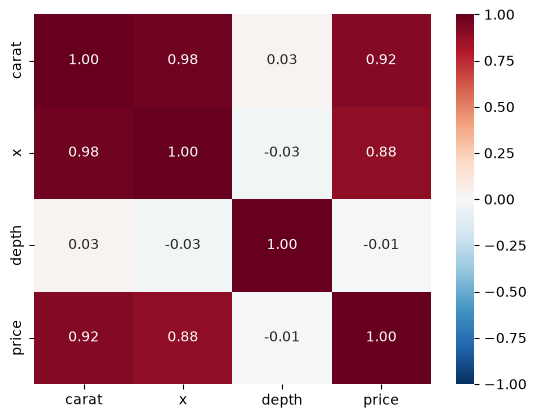

In [60]:
corr = df[["carat", "x", "depth", "price"]].corr()   # x is the diamond's length in mm
print(corr.round(2))
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)   # draws Figure 3-5

The wine recognition dataset bundled with scikit-learn, 178 Italian wines described by 13 chemical measurements and grouped into three cultivars, makes the point.

In [61]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd

wine = load_wine()                                  # 178 wines, 13 measurements, 3 cultivars
X = StandardScaler().fit_transform(wine.data)       # PCA is scale-sensitive, so standardize first
pca = PCA(n_components=2)
coords = pca.fit_transform(X)                        # project 178x13 down to 178x2
print("from", wine.data.shape[1], "features to", coords.shape[1], "components")
print("variance kept:", pca.explained_variance_ratio_.round(2),
      "sum", pca.explained_variance_ratio_.sum().round(2))
proj = pd.DataFrame(coords, columns=["PC1", "PC2"]); proj["cultivar"] = wine.target
print(proj.groupby("cultivar")[["PC1", "PC2"]].mean().round(2))

from 13 features to 2 components
variance kept: [0.36 0.19] sum 0.55
           PC1   PC2
cultivar            
0         2.28  0.97
1        -0.04 -1.64
2        -2.75  1.24


The clusters add something redundancy alone does not promise, that in this dataset the differences between the cultivars are themselves a main source of that shared movement, and a short check on the same standardized data confirms it.

In [62]:
import numpy as np

def mean_abs_corr(M):
    """Average size of the correlations between different columns of M."""
    C = np.corrcoef(M, rowvar=False)
    return np.abs(C[~np.eye(len(C), dtype=bool)]).mean()

y = wine.target
X_within = X.copy()
for k in range(3):                    # subtract each cultivar's own mean from its wines
    X_within[y == k] -= X_within[y == k].mean(axis=0)
print("mean |r| pooled          : %.3f" % mean_abs_corr(X))          # 0.305
print("mean |r| within cultivars: %.3f" % mean_abs_corr(X_within))   # 0.149

pc1 = coords[:, 0]                    # each wine's PC1 coordinate from the PCA fit
between = sum((y == k).sum() * (pc1[y == k].mean() - pc1.mean()) ** 2 for k in range(3))
share = between / ((pc1 - pc1.mean()) ** 2).sum()
print("PC1 variance between cultivars: %.2f" % share)                # 0.80

mean |r| pooled          : 0.305
mean |r| within cultivars: 0.149
PC1 variance between cultivars: 0.80


Correlate bill length against bill depth over all the birds at once and the two look mildly negatively related; facet the same scatter by species and every panel tilts upward instead.

pooled correlation: -0.23
  Adelie     r = +0.39  (n = 146)
  Chinstrap  r = +0.65  (n = 68)
  Gentoo     r = +0.65  (n = 119)


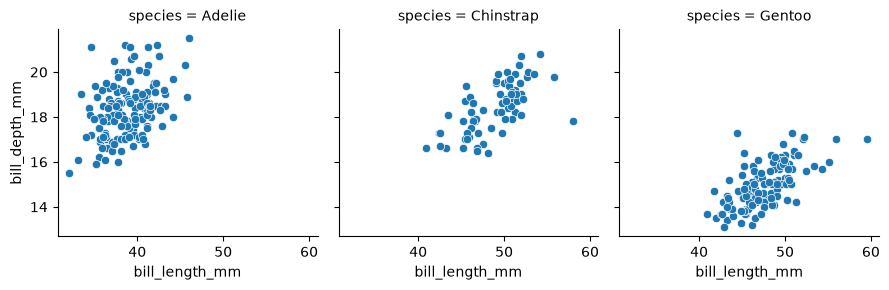

In [63]:
import seaborn as sns

# Palmer penguins (Gorman, Williams, and Fraser 2014), loaded through seaborn's load_dataset.
pen = sns.load_dataset("penguins").dropna()          # 333 complete rows

# Pooled: correlate the two bill measurements over all 333 birds at once.
print("pooled correlation:", round(pen["bill_length_mm"].corr(pen["bill_depth_mm"]), 2))  # -0.23

# Within each species, on that subgroup alone.
for name, g in pen.groupby("species"):
    r = round(g["bill_length_mm"].corr(g["bill_depth_mm"]), 2)
    print(f"  {name:10s} r = {r:+.2f}  (n = {len(g)})")
# Adelie +0.39 (146), Chinstrap +0.65 (68), Gentoo +0.65 (119)

# Small multiples: one scatter panel per species, all on a shared scale.
sns.relplot(data=pen, x="bill_length_mm", y="bill_depth_mm", col="species", height=3)

The Wisconsin breast-cancer data in scikit-learn (569 tumors from load_breast_cancer) shows this starkly, because a tumor's mean perimeter and mean area are near-perfect functions of its mean radius.

In [64]:
import statsmodels.api as sm
from sklearn.datasets import load_breast_cancer
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = load_breast_cancer(as_frame=True).frame
cols = ["mean radius", "mean perimeter", "mean area", "mean smoothness"]
Xc = sm.add_constant(X[cols])                  # VIF needs an intercept column
vif = [round(float(variance_inflation_factor(Xc.values, j)), 1)
       for j in range(1, Xc.shape[1])]
print(dict(zip(cols, vif)))
# {'mean radius': 361.1, 'mean perimeter': 352.8, 'mean area': 40.4, 'mean smoothness': 1.5}

{'mean radius': 361.1, 'mean perimeter': 352.8, 'mean area': 40.4, 'mean smoothness': 1.5}


## 3.4.4 Principles of effective visualization

A simple model shows what that can cost: suppose a reader compares two bubbles by their radii rather than their areas.

In [65]:
import numpy as np
# Two values that differ by 4 percent.
a, b = 100.0, 104.0
length_ratio = b / a              # a BAR encodes value as length: the eye reads this directly
radius_ratio = np.sqrt(b / a)     # a BUBBLE with area proportional to value, compared by radius
print(f"true difference:  {b/a - 1:.1%}")                      # -> true difference:  4.0%
print(f"as bar length:    {length_ratio - 1:.1%} apparent")   # -> as bar length:    4.0% apparent
print(f"as bubble radius: {radius_ratio - 1:.1%} apparent")   # -> as bubble radius: 2.0% apparent

true difference:  4.0%
as bar length:    4.0% apparent
as bubble radius: 2.0% apparent


Its overall survival rate is a single figure, best shown as text, while survival broken out by passenger class is a short set of exact values a table reports more precisely than any bar.

In [66]:
import seaborn as sns
titanic = sns.load_dataset("titanic")            # 891 real passenger records
rate = titanic["survived"].mean()                # one number: show it as text
print(f"Overall survival rate: {rate:.1%}")      # Overall survival rate: 38.4%

Overall survival rate: 38.4%


Figure 3-7 shows the same three numbers, 102, 100, and 104, drawn both ways.

(99.0, 105.0)

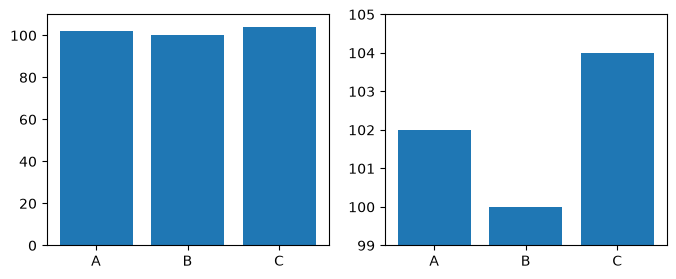

In [67]:
import matplotlib.pyplot as plt
cats, vals = ["A", "B", "C"], [102, 100, 104]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.bar(cats, vals); ax1.set_ylim(0, 110)     # honest: baseline at zero
ax2.bar(cats, vals); ax2.set_ylim(99, 105)    # misleading: truncated axis

The California housing data from 3.4.2 demonstrates the trick; its 20,640 rows are census block groups, which scikit-learn's description of the dataset also refers to as districts, the word the next block uses.

In [68]:
from sklearn.datasets import fetch_california_housing

df = fetch_california_housing(as_frame=True).frame   # 20,640 California districts, 1990 U.S. census
full = df["MedInc"].corr(df["MedHouseVal"])           # income vs home value, all districts
rich = df[df["MedInc"] > 9]                           # cherry-pick: only the richest districts
sub = rich["MedInc"].corr(rich["MedHouseVal"])
print("all districts :", len(df), " corr =", round(full, 2))               # 20640  corr = 0.69
print("richest only  :", len(rich), "  corr =", round(sub, 2))             # 407  corr = 0.12
print("capped at $500k among the rich:", round((rich["MedHouseVal"] >= 5).mean(), 2))  # 0.81

all districts : 20640  corr = 0.69
richest only  : 407   corr = 0.12
capped at $500k among the rich: 0.81


Figure 3-8 contrasts a sequential scale with a qualitative one.

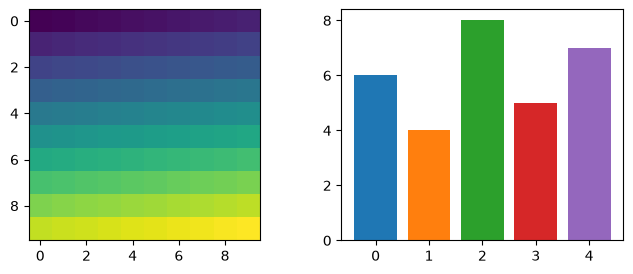

In [69]:
import numpy as np
grid = np.linspace(0, 1, 100).reshape(10, 10)
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3))
a.imshow(grid, cmap="viridis")                       # sequential: ordered magnitude
for i in range(5):
    b.bar(i, [6, 4, 8, 5, 7][i], color=plt.cm.tab10(i))   # qualitative: distinct categories

Figure 3-9 shows five thousand points three ways. The points, in the figure and in the next block, are synthetic: random draws from a normal distribution in which y rises with x, so the shape of the cloud is known in advance and it is easy to judge which rendering recovers it.

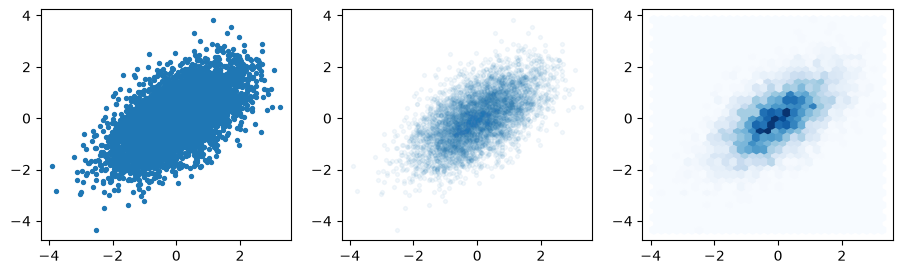

In [70]:
x = np.random.default_rng(0).normal(0, 1, 5000); y = x * 0.6 + np.random.default_rng(1).normal(0, 0.8, 5000)
fig, (a, b, c) = plt.subplots(1, 3, figsize=(11, 3))
a.scatter(x, y, s=8)                       # opaque: a featureless blob
b.scatter(x, y, s=8, alpha=0.05)           # transparent: density emerges
c.hexbin(x, y, gridsize=30, cmap="Blues")  # binned: density as color

Matplotlib draws both directly, ax.errorbar for the whiskered point and ax.fill_between for the band. Example 3-9 computes both intervals from their formulas on the Palmer penguins and draws them side by side, the two panels of Figure 3-10.

means (g): {'Adelie': 3701.0, 'Chinstrap': 3733.0, 'Gentoo': 5076.0}
95% CI +/-: {'Adelie': 73.0, 'Chinstrap': 91.0, 'Gentoo': 89.0}
slope g/mm: 49.7  band half-width mid-range: 42.0
t: 1.967  s: 394.3  xbar: 200.92  Sxx: 67427  edge half-widths: [96.0, 99.2]


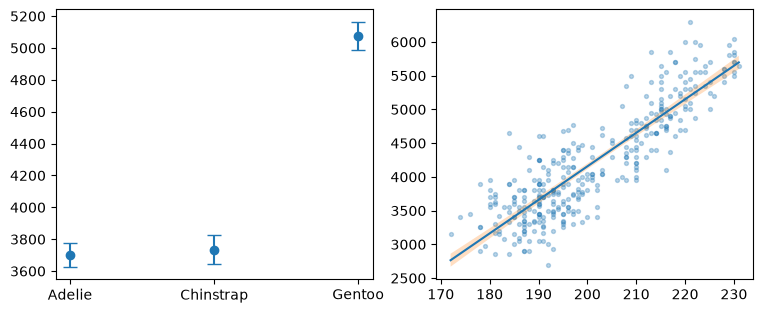

In [71]:
import numpy as np, seaborn as sns, matplotlib.pyplot as plt
from scipy import stats
pen = sns.load_dataset("penguins").dropna(subset=["species", "body_mass_g", "flipper_length_mm"])

g = pen.groupby("species")["body_mass_g"]
means = g.mean()
sem = g.std(ddof=1) / np.sqrt(g.count())        # standard error of the mean: s / sqrt(n)
ci95 = 1.96 * sem                               # 95% confidence half-width

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.errorbar(means.index, means.values, yerr=ci95.values, fmt="o", capsize=5)   # point + whisker

x = pen["flipper_length_mm"].to_numpy(); y = pen["body_mass_g"].to_numpy(); n = len(x)
b1, b0 = np.polyfit(x, y, 1)                     # slope, intercept of the fitted line
s = np.sqrt(((y - (b0 + b1 * x)) ** 2).sum() / (n - 2))     # residual standard error
xbar = x.mean(); Sxx = ((x - xbar) ** 2).sum()
xs = np.linspace(x.min(), x.max(), 100)
band = stats.t.ppf(0.975, n - 2) * s * np.sqrt(1 / n + (xs - xbar) ** 2 / Sxx)
line = b0 + b1 * xs
ax2.scatter(x, y, s=8, alpha=0.3); ax2.plot(xs, line)
ax2.fill_between(xs, line - band, line + band, alpha=0.25)   # 95% confidence band

print("means (g):", means.round(0).to_dict())   # Adelie 3701, Chinstrap 3733, Gentoo 5076
print("95% CI +/-:", ci95.round(0).to_dict())   # 73, 91, 89
print("slope g/mm:", round(b1, 1), " band half-width mid-range:", round(float(band[50]), 0))  # 49.7, 42.0
print("t:", round(stats.t.ppf(0.975, n - 2), 3), " s:", round(s, 1), " xbar:", round(xbar, 2),
      " Sxx:", round(Sxx), " edge half-widths:", band[[0, -1]].round(1).tolist())   # 1.967 394.3 200.92 67427 [96.0, 99.2]

In matplotlib you choose the format simply by the filename extension you pass to savefig.

In [72]:
import os
import matplotlib
matplotlib.use("Agg")            # headless backend: render straight to a file, no screen needed
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True).frame   # 20,640 real 1990-census districts

# A simple chart: only a handful of drawn elements (a few bars).
fig1, ax1 = plt.subplots(figsize=(5, 3))
means = data.groupby(data["HouseAge"].round(-1))["MedHouseVal"].mean()
ax1.bar(means.index.astype(int).astype(str), means.values)
for ext in ("png", "svg", "pdf"):
    fig1.savefig(f"simple.{ext}", dpi=300, bbox_inches="tight")   # format = filename extension

# A dense chart: 20,640 individual points, one shape each in a vector file.
fig2, ax2 = plt.subplots(figsize=(5, 3))
ax2.scatter(data["MedInc"], data["MedHouseVal"], s=4, alpha=0.3)
for ext in ("png", "svg", "pdf"):
    fig2.savefig(f"dense.{ext}", dpi=300, bbox_inches="tight")

for name in ("simple", "dense"):
    kb = {ext: os.path.getsize(f"{name}.{ext}") // 1024 for ext in ("png", "svg", "pdf")}
    print(f"{name:6s} KB:", kb)
# simple KB: {'png': 22, 'svg': 11, 'pdf': 5}
# dense  KB: {'png': 343, 'svg': 2946, 'pdf': 251}

simple KB: {'png': 22, 'svg': 11, 'pdf': 5}
dense  KB: {'png': 343, 'svg': 2946, 'pdf': 251}


Notebook helper, not a book block: the block above selected the headless Agg backend and left its two saved figures open, so this closes them and, inside Jupyter, switches back to the inline backend so the figures of the cells that follow are embedded again; a plain python run keeps Agg.

In [73]:
import os as _os                        # notebook helper, not part of the book text:
import matplotlib                       # the savefig block selected Agg and left its two
import matplotlib.pyplot as plt         # figures open; close them so they are not shown
plt.close("all")                        # again, then, inside Jupyter, switch back to
try:                                    # inline so later figures embed
    get_ipython().run_line_magic("matplotlib", "inline")   # a plain python run keeps Agg
except NameError:
    matplotlib.use("Agg")

## 3.4.5 Telling a story with data

Figure 3-11 shows these moves applied to one line among several. Its data, like that of the next block, is synthetic: the block types in twelve months of sales for one company and makes four competitor lines by adding random noise to that series, because the point here is the design rather than the numbers.

Text(0.5, 1.0, 'Sales rose through July, then declined for five straight months')

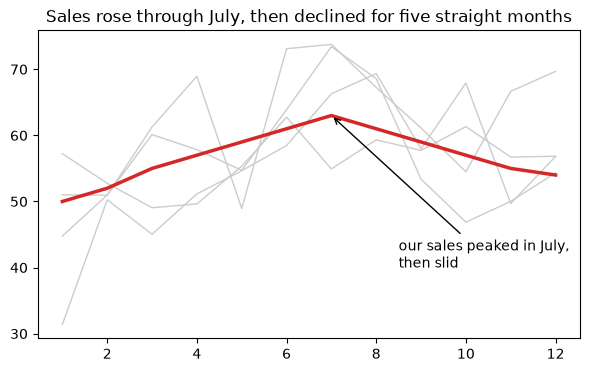

In [74]:
months = np.arange(1, 13)
ours = np.array([50, 52, 55, 57, 59, 61, 63, 61, 59, 57, 55, 54])   # peaks at 63 in July, then falls five months
rng = np.random.default_rng(0)
competitors = [ours + rng.normal(0, 8, 12) for _ in range(4)]   # four context series
fig, ax = plt.subplots(figsize=(7, 4))
for comp in competitors:                       # context: thin, light gray, no labels
    ax.plot(months, comp, color="0.8", linewidth=1)
ax.plot(months, ours, color="C3", linewidth=2.5)         # message: bold and colored
ax.annotate("our sales peaked in July,\nthen slid", xy=(7, 63), xytext=(8.5, 40),
            arrowprops=dict(arrowstyle="->"))            # annotate directly, no legend
ax.set_title("Sales rose through July, then declined for five straight months")

## 3.4.6 Comparing a numeric variable across groups: densities, violins, strips, and swarms

In [75]:
import numpy as np

# two groups of nine values: one clumped at 2 and 6, one spread evenly from 0 to 8
clumped = np.array([0, 2, 2, 2, 4, 6, 6, 6, 8], dtype=float)
even = np.arange(9, dtype=float)
for name, v in (("clumped", clumped), ("even", even)):
    print(name, "min, Q1, median, Q3, max:", np.percentile(v, [0, 25, 50, 75, 100]))

def kde_at(points, data, h):
    # the Gaussian kernel density estimate of 2.4.15, evaluated at a few points
    u = (np.asarray(points, dtype=float)[:, None] - data[None, :]) / h
    return np.exp(-u**2 / 2).sum(axis=1) / (len(data) * h * np.sqrt(2 * np.pi))

for name, v in (("clumped", clumped), ("even", even)):
    print(name, "density at 2, 4, 6:", np.round(kde_at([2, 4, 6], v, h=1.0), 4))

clumped min, Q1, median, Q3, max: [0. 2. 4. 6. 8.]
even min, Q1, median, Q3, max: [0. 2. 4. 6. 8.]
clumped density at 2, 4, 6: [0.145  0.0804 0.145 ]
even density at 2, 4, 6: [0.1106 0.1111 0.1106]


In [76]:
import matplotlib
matplotlib.use("Agg")                                   # draw straight to files, no screen needed
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

birds = sns.load_dataset("penguins").dropna(subset=["flipper_length_mm"])    # 342 Palmer penguins
print(birds.groupby("island")["flipper_length_mm"].describe()[["count", "mean", "25%", "50%", "75%"]])

biscoe = birds.loc[birds["island"] == "Biscoe", "flipper_length_mm"].to_numpy()
kde_b = stats.gaussian_kde(biscoe)                      # Scott's rule, seaborn's default bandwidth too
h_b = float(np.sqrt(kde_b.covariance[0, 0]))            # that bandwidth in millimeters
grid = np.linspace(150, 250, 2001)

def peaks(dens):
    # grid points higher than both neighbors: the humps of the curve
    return grid[1:-1][(dens[1:-1] > dens[:-2]) & (dens[1:-1] > dens[2:])]

print("Biscoe: h =", round(h_b, 2), "mm | density peaks at", np.round(peaks(kde_b(grid)), 1), "mm")
print("species on Biscoe:", birds.loc[birds["island"] == "Biscoe", "species"].value_counts().to_dict())
print("default violin spans", round(biscoe.min() - 2 * h_b, 1), "to", round(biscoe.max() + 2 * h_b, 1),
      "mm for data from", biscoe.min(), "to", biscoe.max())
for adjust in (0.25, 1, 3):                             # what seaborn's bw_adjust does to the bandwidth
    smooth = stats.gaussian_kde(biscoe, bw_method=kde_b.factor * adjust)
    print("bw_adjust", adjust, "-> peaks at", np.round(peaks(smooth(grid)), 1))

order = ["Biscoe", "Dream", "Torgersen"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey=True)
sns.boxplot(data=birds, x="island", y="flipper_length_mm", order=order, ax=axes[0, 0])
sns.violinplot(data=birds, x="island", y="flipper_length_mm", order=order, ax=axes[0, 1])
sns.stripplot(data=birds, x="island", y="flipper_length_mm", order=order, alpha=0.5, ax=axes[1, 0])
sns.swarmplot(data=birds, x="island", y="flipper_length_mm", order=order, size=3, ax=axes[1, 1])
fig.tight_layout()
fig.savefig("flipper_by_island.png", dpi=150)

fig2, ax2 = plt.subplots(figsize=(6, 3.5))
sns.kdeplot(data=birds, x="flipper_length_mm", hue="island", ax=ax2)     # common_norm=True by default
fig2.savefig("flipper_kde_by_island.png", dpi=150, bbox_inches="tight")
areas = sorted(round(float(np.trapezoid(ln.get_ydata(), ln.get_xdata())), 3) for ln in ax2.lines)
print("areas under the three curves:", areas,
      "| island shares:", sorted((birds["island"].value_counts() / len(birds)).round(3).tolist()))
print("drawn peak heights:", sorted(round(float(ln.get_ydata().max()), 4) for ln in ax2.lines))
print("peak of each island's own density:", {island: round(float(stats.gaussian_kde(g)(grid).max()), 4)
                                            for island, g in birds.groupby("island")["flipper_length_mm"]})

           count        mean     25%    50%    75%
island                                            
Biscoe     167.0  209.706587  199.50  214.0  220.0
Dream      124.0  193.072581  187.75  193.0  198.0
Torgersen   51.0  191.196078  187.00  191.0  195.0
Biscoe: h = 5.08 mm | density peaks at [189.3 215.6] mm
species on Biscoe: {'Gentoo': 123, 'Adelie': 44}
default violin spans 161.8 to 241.2 mm for data from 172.0 to 231.0
bw_adjust 0.25 -> peaks at [173.  180.6 185.9 191.5 202.9 209.6 215.2 219.9 229.5]
bw_adjust 1 -> peaks at [189.3 215.6]
bw_adjust 3 -> peaks at [214.]


areas under the three curves: [0.149, 0.363, 0.488] | island shares: [0.149, 0.363, 0.488]
drawn peak heights: [0.0089, 0.0172, 0.0184]
peak of each island's own density: {'Biscoe': 0.0353, 'Dream': 0.0507, 'Torgersen': 0.0594}


## 3.4.7 Two categorical variables: crosstabs and Cramér's V

In [77]:
import numpy as np, pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

ship = sns.load_dataset("titanic")                       # the 891 passengers of 3.4.1
print(pd.crosstab(ship["sex"], ship["survived"]))
print(pd.crosstab(ship["sex"], ship["survived"], normalize="index").round(3))   # each row sums to 1

def cramers_v(table):
    """Cramer's V of a table of counts: chi-square rescaled to run from 0 to 1."""
    chi2 = chi2_contingency(table, correction=False).statistic
    n_rows, n_cols = table.shape
    return float((chi2 / (table.to_numpy().sum() * (min(n_rows, n_cols) - 1))) ** 0.5)

for left, right in [("sex", "survived"), ("class", "survived"), ("sex", "who"), ("sex", "embark_town")]:
    tab = pd.crosstab(ship[left], ship[right])
    test = chi2_contingency(tab, correction=False)
    print(f"{left} x {right}: chi2 = {test.statistic:.2f}, p = {test.pvalue:.3g}, "
          f"V = {cramers_v(tab):.4f}, SciPy's V = {association(tab.to_numpy()):.4f}")
print("phi as a Pearson correlation:", round(np.corrcoef(ship["sex"] == "male", ship["survived"])[0, 1], 4))

weak = pd.crosstab(ship["sex"], ship["embark_town"])
for times in (10, 100):                                  # the same proportions, more passengers
    test = chi2_contingency(weak * times, correction=False)
    print(f"x{times}: chi2 = {test.statistic:.1f}, p = {test.pvalue:.3g}, V = {cramers_v(weak * times):.4f}")

port = ship.dropna(subset=["embark_town"])
for codes in ({"Cherbourg": 0, "Queenstown": 1, "Southampton": 2},
              {"Southampton": 0, "Cherbourg": 1, "Queenstown": 2}):
    print("Pearson r, ports coded", list(codes), "=", round(port["embark_town"].map(codes).corr(port["survived"]), 4))
print("Cramer's V, port x survived =", round(cramers_v(pd.crosstab(port["embark_town"], port["survived"])), 4))

shares = pd.crosstab(ship["class"], ship["survived"], normalize="index")
ax3 = shares.plot(kind="bar", stacked=True, figsize=(5, 3.5), rot=0)     # one 100 percent bar per class
ax3.set_ylabel("share of passengers")
ax3.legend(title="survived", loc="upper left", bbox_to_anchor=(1.0, 1.0))  # keep the key off the bars
ax3.figure.savefig("survival_by_class.png", dpi=150, bbox_inches="tight")
print(shares.round(3))

survived    0    1
sex               
female     81  233
male      468  109
survived      0      1
sex                   
female    0.258  0.742
male      0.811  0.189
sex x survived: chi2 = 263.05, p = 3.71e-59, V = 0.5434, SciPy's V = 0.5434
class x survived: chi2 = 102.89, p = 4.55e-23, V = 0.3398, SciPy's V = 0.3398
sex x who: chi2 = 800.20, p = 1.74e-174, V = 0.9477, SciPy's V = 0.9477
sex x embark_town: chi2 = 13.36, p = 0.00126, V = 0.1226, SciPy's V = 0.1226
phi as a Pearson correlation: -0.5434
x10: chi2 = 133.6, p = 9.97e-30, V = 0.1226
x100: chi2 = 1335.6, p = 9.69e-291, V = 0.1226
Pearson r, ports coded ['Cherbourg', 'Queenstown', 'Southampton'] = -0.1697
Pearson r, ports coded ['Southampton', 'Cherbourg', 'Queenstown'] = 0.1087
Cramer's V, port x survived = 0.1726
survived      0      1
class                 
First     0.370  0.630
Second    0.527  0.473
Third     0.758  0.242


## 3.5.1 Encoding categorical features

Target encoding replaces a category with the mean of the target for that category, which is compact for high-cardinality features like ZIP code but dangerous, because using the target to build a feature is a direct path to leakage unless it

In [78]:
import pandas as pd, seaborn as sns
df = sns.load_dataset("titanic")                                 # 891 real passengers

# embarkation port is nominal (three ports, no order): one-hot it
print(list(pd.get_dummies(df["embarked"], prefix="port").columns))          # ['port_C', 'port_Q', 'port_S']
print(list(pd.get_dummies(df["embarked"], prefix="port", drop_first=True).columns))  # ['port_Q', 'port_S']

# travel class is ordinal (First > Second > Third): map to ordered integers
order = {"Third": 0, "Second": 1, "First": 2}
print(df["class"].map(order).head(3).tolist())                   # [0, 2, 0]

['port_C', 'port_Q', 'port_S']
['port_Q', 'port_S']
[0, 2, 0]


In scikit-learn the encoder for features is OrdinalEncoder; LabelEncoder is documented for target values, the y, and not the input X.

In [79]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, export_text

ports = df[["embarked"]].dropna()            # 889 passengers with a recorded port
enc = OrdinalEncoder()                       # the feature-side integer encoder
codes = enc.fit_transform(ports)             # one column of codes, not three
print(enc.categories_[0].tolist(), codes[:5].ravel().tolist())   # ['C', 'Q', 'S'] [2.0, 0.0, 2.0, 2.0, 2.0]
tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(codes, df.loc[ports.index, "survived"])
print(export_text(tree, feature_names=["port_code"]))

['C', 'Q', 'S'] [2.0, 0.0, 2.0, 2.0, 2.0]
|--- port_code <= 0.50
|   |--- class: 1
|--- port_code >  0.50
|   |--- port_code <= 1.50
|   |   |--- class: 0
|   |--- port_code >  1.50
|   |   |--- class: 0



The Titanic's deck column, recorded for 203 passengers across seven decks with groups as small as four, shows the gap.

In [80]:
import pandas as pd, seaborn as sns
from sklearn.model_selection import KFold

known = sns.load_dataset("titanic").dropna(subset=["deck"]).reset_index(drop=True)
cat, y = known["deck"], known["survived"]           # 203 passengers with a recorded deck
print(cat.value_counts().to_dict())
# {'C': 59, 'B': 47, 'D': 33, 'E': 32, 'A': 15, 'F': 13, 'G': 4}
print("deck G survivors:", int(y[cat == "G"].sum()), "of", int((cat == "G").sum()),
      "| global rate:", round(y.mean(), 3))                   # 2 of 4 | global rate: 0.67

# naive target encoding: each deck's mean survival computed on ALL rows
naive = cat.map(y.groupby(cat, observed=True).mean())

# out-of-fold: each fold is encoded with means learned on the other folds only
oof = pd.Series(index=known.index, dtype=float)
for tr, va in KFold(5, shuffle=True, random_state=0).split(known):
    means = y.iloc[tr].groupby(cat.iloc[tr], observed=True).mean()
    oof.iloc[va] = cat.iloc[va].map(means).to_numpy()
oof = oof.fillna(y.mean())   # a fold can miss a rare deck entirely: back off to the global rate

print("naive corr with target:", round(naive.corr(y), 3))   # 0.203
print("out-of-fold corr      :", round(oof.corr(y), 3))     # 0.08

# the standard tool: scikit-learn's TargetEncoder cross-fits and smooths internally
from sklearn.preprocessing import TargetEncoder
te = TargetEncoder(cv=KFold(5, shuffle=True, random_state=0)).fit_transform(
    known[["deck"]].astype(str), y).ravel()
print("TargetEncoder corr    :", round(pd.Series(te).corr(y), 3))   # 0.077

{'C': 59, 'B': 47, 'D': 33, 'E': 32, 'A': 15, 'F': 13, 'G': 4}
deck G survivors: 2 of 4 | global rate: 0.67
naive corr with target: 0.203
out-of-fold corr      : 0.08
TargetEncoder corr    : 0.077


In [81]:
import pandas as pd, seaborn as sns
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

ship = sns.load_dataset("titanic")
port_rows = ship[["embarked"]].dropna()                # the 889 passengers with a recorded port
one_new = pd.DataFrame({"embarked": ["Q"]})            # one passenger arriving at prediction time

# get_dummies sees only the rows in front of it: one new row yields one column, not three
print(pd.get_dummies(port_rows["embarked"]).columns.tolist(),
      pd.get_dummies(one_new["embarked"]).columns.tolist())

# a fitted OneHotEncoder remembers the training categories and always emits their full width
ohe = OneHotEncoder(handle_unknown="ignore").fit(port_rows)
print(ohe.categories_[0].tolist(), ohe.transform(one_new).toarray().tolist())
print(ohe.transform(pd.DataFrame({"embarked": ["Southampton"]})).toarray().tolist())   # unseen spelling

# OrdinalEncoder with an explicit order does the job of the hand-written dict map
cls_enc = OrdinalEncoder(categories=[["Third", "Second", "First"]]).fit(ship[["class"]])
print(cls_enc.transform(ship[["class"]].head(3)).ravel().tolist())

# what the width mismatch does to a fitted model, and what the default handle_unknown="error" does
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression().fit(pd.get_dummies(port_rows["embarked"]), ship.loc[port_rows.index, "survived"])
try:
    clf.predict(pd.get_dummies(one_new["embarked"]))
except ValueError as err:
    print("model fit on three dummy columns:", str(err).splitlines()[0])
try:
    OneHotEncoder().fit(port_rows).transform(pd.DataFrame({"embarked": ["Southampton"]}))
except ValueError as err:
    print("default encoder:", err)

['C', 'Q', 'S'] ['Q']
['C', 'Q', 'S'] [[0.0, 1.0, 0.0]]
[[0.0, 0.0, 0.0]]
[0.0, 2.0, 0.0]
model fit on three dummy columns: The feature names should match those that were passed during fit.
default encoder: Found unknown categories ['Southampton'] in column 0 during transform


## 3.5.2 Scaling numeric features

Normalization, or min-max scaling, rescales a feature linearly into the range zero to one.

In [82]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
std = StandardScaler().fit_transform(df[["fare"]])
mm = MinMaxScaler().fit_transform(df[["fare"]])
print("standardized: mean=%.2f std=%.2f" % (std.mean(), std.std()))   # mean=0.00 std=1.00
print("min-max: min=%.2f max=%.2f" % (mm.min(), mm.max()))            # min=0.00 max=1.00
print("fare mean=%.2f std=%.2f min=%.2f max=%.2f" % (
    df["fare"].mean(), df["fare"].std(ddof=0), df["fare"].min(), df["fare"].max()))
# fare mean=32.20 std=49.67 min=0.00 max=512.33   (ddof=0: StandardScaler divides by n)

standardized: mean=0.00 std=1.00
min-max: min=0.00 max=1.00
fare mean=32.20 std=49.67 min=0.00 max=512.33


## 3.5.3 Transforming features

Polynomial features add powers and products of existing features, letting a linear model fit curves, and an interaction term, the product of two features, captures an effect that appears only when both are present, such as being both young

In [83]:
import numpy as np
pos_fare = df.loc[df["fare"] > 0, "fare"]        # the log needs strictly positive values
print("fare skew:", round(pos_fare.skew(), 2),                            # 4.77
      "-> log-fare skew:", round(np.log(pos_fare).skew(), 2))             # 0.9

df["age_bin"] = pd.cut(df["age"], bins=[0, 12, 60, 100],
                       labels=["child", "adult", "senior"])
print(df["age_bin"].value_counts().to_dict())    # {'adult': 623, 'child': 69, 'senior': 22}

from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False).fit(df[["age", "fare"]].dropna())
print(list(poly.get_feature_names_out(["age", "fare"])))
# ['age', 'fare', 'age^2', 'age fare', 'fare^2']

fare skew: 4.77 -> log-fare skew: 0.9
{'adult': 623, 'child': 69, 'senior': 22}
['age', 'fare', 'age^2', 'age fare', 'fare^2']


A good test column is the fare paid by the 891 passengers in the Titanic dataset, loaded here from seaborn, which is strongly right skewed and, tellingly, includes 15 tickets recorded at a fare of zero.

In [84]:
import numpy as np, pandas as pd, seaborn as sns
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import train_test_split

fare = sns.load_dataset("titanic")["fare"].dropna().to_frame()   # 891 real ticket fares
print("raw skew:", round(fare["fare"].skew(), 2),
      "| zero-fare rows:", int((fare["fare"] == 0).sum()))        # 4.79 | 15

# Yeo-Johnson tunes lambda by maximum likelihood and accepts the zero fares
yj = PowerTransformer(method="yeo-johnson").fit(fare)
print("Yeo-Johnson lambda:", round(yj.lambdas_[0], 3),
      "-> skew:", round(pd.Series(yj.transform(fare).ravel()).skew(), 2))   # -0.098 -> -0.04

# Box-Cox needs strictly positive x, so it must skip the zero fares
pos = fare[fare["fare"] > 0]
bc = PowerTransformer(method="box-cox").fit(pos)
print("Box-Cox lambda:", round(bc.lambdas_[0], 3),
      "-> skew:", round(pd.Series(bc.transform(pos).ravel()).skew(), 2))    # -0.524 -> 0.22
print("plain log-fare skew:", round(np.log(pos["fare"]).skew(), 2))         # 0.9

# fit lambda on the training split alone, then reuse it on the test split
tr, te = train_test_split(pos, test_size=0.2, random_state=0)
pt = PowerTransformer(method="box-cox").fit(tr)
print("train skew:", round(pd.Series(pt.transform(tr).ravel()).skew(), 2),
      "| test skew:", round(pd.Series(pt.transform(te).ravel()).skew(), 2))  # 0.2 | 0.39

raw skew: 4.79 | zero-fare rows: 15
Yeo-Johnson lambda: -0.098 -> skew: -0.04
Box-Cox lambda: -0.524 -> skew: 0.22
plain log-fare skew: 0.9
train skew: 0.2 | test skew: 0.39


## 3.5.4 Features from dates, text, and domain knowledge

Other features come from domain knowledge, quantities an expert knows to compute, such as price per square foot or a debt-to-income ratio. Domingos (2012, page 84) gives the reason they resist automation: feature engineering is specific to each domain, while learning algorithms can be largely general purpose, and in 2012 he still counted automating more of it as "one of the holy grails of machine learning."

In [85]:
dates = pd.to_datetime(pd.Series(["2010-05-01", "2018-11-23", "2022-02-14"]))
print(dates.dt.year.tolist(), dates.dt.month.tolist())     # [2010, 2018, 2022] [5, 11, 2]
print(dates.dt.day_name().tolist())                         # ['Saturday', 'Friday', 'Monday']
print((dates.dt.dayofweek >= 5).tolist())                   # [True, False, False]   is-weekend flag

descriptions = pd.Series(["cozy home near the park", "spacious modern loft downtown"])
print(descriptions.str.len().tolist())                      # [23, 29]   characters
print(descriptions.str.split().str.len().tolist())          # [5, 4]     words

[2010, 2018, 2022] [5, 11, 2]
['Saturday', 'Friday', 'Monday']
[True, False, False]
[23, 29]
[5, 4]


A domain ratio like the price per square foot above takes one line on real data: price per carat on the seaborn diamonds of 3.4.

In [86]:
import numpy as np, seaborn as sns

month = dates.dt.month
print(np.sin(2 * np.pi * month / 12).round(3).tolist(),     # cyclical month: a point on a circle
      np.cos(2 * np.pi * month / 12).round(3).tolist())     # [0.5, -0.5, 0.866] [-0.866, 0.866, 0.5]
def on_circle(m):
    return np.array([np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)])
print(round(float(np.linalg.norm(on_circle(12) - on_circle(1))), 3),     # December to January: 0.518
      round(float(np.linalg.norm(on_circle(1) - on_circle(2))), 3))      # January to February: 0.518

dia = sns.load_dataset("diamonds")                          # 53,940 real diamonds
dia["price_per_carat"] = dia["price"] / dia["carat"]        # a domain ratio feature
print(dia.groupby("cut", observed=True)[["carat", "price", "price_per_carat"]].median()
      .round({"carat": 2, "price": 0, "price_per_carat": 0}))

[0.5, -0.5, 0.866] [-0.866, 0.866, 0.5]
0.518 0.518
           carat   price  price_per_carat
cut                                      
Ideal       0.54  1810.0           3307.0
Premium     0.86  3185.0           3763.0
Very Good   0.71  2648.0           3606.0
Good        0.82  3050.0           3613.0
Fair        1.00  3282.0           3449.0


In [87]:
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

bike = fetch_openml(data_id=42712, as_frame=True).frame      # the hourly rentals of 3.3.7
hour, rides = bike["hour"].to_numpy(), bike["count"].to_numpy()
print("mean rides at 8:00 and 17:00:", bike.groupby("hour")["count"].mean().round(1).loc[[8, 17]].tolist())
angle = 2 * np.pi * hour / 24
encodings = {
    "raw hour": hour.reshape(-1, 1),
    "sin, cos": np.column_stack([np.sin(angle), np.cos(angle)]),
    "4 harmonics": np.column_stack([f(k * angle) for k in (1, 2, 3, 4) for f in (np.sin, np.cos)]),
    "one-hot hour": pd.get_dummies(bike["hour"], dtype=float).to_numpy(),
}
cut = int(0.75 * len(bike))                  # rows run in time order: fit on the first three quarters
print("test rows: year", bike.loc[cut, "year"], "month", bike.loc[cut, "month"],
      "to year", bike.iloc[-1]["year"], "month", bike.iloc[-1]["month"])   # year 1 month 7 to year 1 month 12
for name, X in encodings.items():
    lr = LinearRegression().fit(X[:cut], rides[:cut])
    late, midnight = lr.predict(X[[np.argmax(hour == 23), np.argmax(hour == 0)]])
    print(f"{name:12s} {X.shape[1]:2d} columns | test R2 {r2_score(rides[cut:], lr.predict(X[cut:])):.3f}"
          f" | 23:00 -> {late:5.1f}, 0:00 -> {midnight:5.1f}")

mean rides at 8:00 and 17:00: [359.0, 461.5]
test rows: year 1 month 7 to year 1 month 12
raw hour      1 columns | test R2 0.008 | 23:00 -> 273.7, 0:00 ->  60.9
sin, cos      2 columns | test R2 0.208 | 23:00 -> 102.5, 0:00 ->  74.8
4 harmonics   8 columns | test R2 0.336 | 23:00 ->  68.7, 0:00 ->  68.1
one-hot hour 24 columns | test R2 0.386 | 23:00 ->  77.5, 0:00 ->  47.4


## 3.5.5 Feature selection

the Lasso of 2.1.6 drives the coefficients of useless features to exactly zero, and the tree ensembles of Chapter 7 report a feature importance for each input.

In [88]:
import numpy as np, seaborn as sns
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

dia = sns.load_dataset("diamonds").copy()
dia["noise"] = np.random.default_rng(0).normal(size=len(dia))   # a deliberately irrelevant column
X, y = dia[["carat", "depth", "noise"]], dia["price"]           # predict price from three features
print(dict(zip(X.columns, SelectKBest(f_regression, k=2).fit(X, y).scores_.round(1).tolist())))
# {'carat': 304050.9, 'depth': 6.1, 'noise': 0.4}

coefs = Lasso(alpha=1000, max_iter=10000).fit(StandardScaler().fit_transform(X), y).coef_
print(dict(zip(X.columns, coefs.round(0).tolist())))   # {'carat': 2677.0, 'depth': -0.0, 'noise': 0.0}

{'carat': 304050.9, 'depth': 6.1, 'noise': 0.4}
{'carat': 2677.0, 'depth': -0.0, 'noise': 0.0}


The wine recognition dataset that ships with scikit-learn, 178 wines described by 13 chemical measurements and labeled with one of three cultivars, shows the filter at work.

In [89]:
from sklearn.datasets import load_wine
from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd

wine = load_wine(as_frame=True)          # 178 wines, 13 chemical measurements
X, y = wine.data, wine.target            # target: one of 3 cultivars (0, 1, 2)

f_scores = SelectKBest(f_classif, k=3).fit(X, y).scores_   # f_classif is also SelectKBest's default
ranked_f = pd.Series(f_scores, index=X.columns).sort_values(ascending=False)
print(ranked_f.round(1).head(4).to_string())
# flavanoids                      233.9
# proline                         207.9
# od280/od315_of_diluted_wines    190.0
# alcohol                         135.1
print("lowest:", ranked_f.index[-1], round(ranked_f.iloc[-1], 1))   # lowest: magnesium 12.4

# the top score by hand: between-class variance over within-class variance (2.4.5)
x = X["flavanoids"]
per_class = x.groupby(y)                                 # one group per cultivar
between = (per_class.size() * (per_class.mean() - x.mean()) ** 2).sum() / (3 - 1)   # k - 1, k = 3 classes
within = ((x - per_class.transform("mean")) ** 2).sum() / (len(x) - 3)              # N - k, N = 178 wines
print(round(between, 2), round(within, 4), round(between / within, 1))   # 64.26 0.2747 233.9

flavanoids                      233.9
proline                         207.9
od280/od315_of_diluted_wines    190.0
alcohol                         135.1
lowest: magnesium 12.4
64.26 0.2747 233.9


Because it is built from counts, `chi2` requires nonnegative features, and running it on the same continuous wine measurements shows why the choice of statistic matters.

In [90]:
from sklearn.datasets import load_wine
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

wine = load_wine(as_frame=True)          # 178 wines, 13 chemical measurements
X, y = wine.data, wine.target            # target: one of 3 cultivars (0, 1, 2)

scores = SelectKBest(chi2, k=3).fit(X, y).scores_
ranked = pd.Series(scores, index=X.columns).sort_values(ascending=False)
print(ranked.round(1).head(4).to_string())
# proline            16540.1
# color_intensity      109.0
# flavanoids            63.3
# magnesium             45.0
print("lowest:", ranked.index[-1], round(ranked.iloc[-1], 2))   # lowest: ash 0.74

# the same filter after rescaling every feature to the range 0 to 1
X01 = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)
scores01 = SelectKBest(chi2, k=3).fit(X01, y).scores_
ranked01 = pd.Series(scores01, index=X.columns).sort_values(ascending=False)
print(ranked01.round(1).head(3).to_string())
# proline                         18.8
# od280/od315_of_diluted_wines    16.7
# flavanoids                      16.1

proline            16540.1
color_intensity      109.0
flavanoids            63.3
magnesium             45.0
lowest: ash 0.74
proline                         18.8
od280/od315_of_diluted_wines    16.7
flavanoids                      16.1


The Titanic passengers from seaborn's `load_dataset`, with sex, travel class, and port of embarkation one-hot encoded into 0/1 indicator columns, show it scoring each indicator against survival.

In [91]:
import pandas as pd, seaborn as sns
from sklearn.feature_selection import chi2

titanic = sns.load_dataset("titanic")                                      # 891 passengers
onehot = pd.get_dummies(titanic[["sex", "class", "embarked"]], dtype=int)  # 0/1 indicator columns
stat = chi2(onehot, titanic["survived"])[0]       # chi2 returns (statistics, p-values)
print(pd.Series(stat, index=onehot.columns).sort_values(ascending=False).round(1).to_string())
# sex_female      170.3
# sex_male         92.7
# class_First      55.2
# class_Third      41.6
# embarked_C       20.5
# class_Second      6.2
# embarked_S        6.0
# embarked_Q        0.0

sex_female      170.3
sex_male         92.7
class_First      55.2
class_Third      41.6
embarked_C       20.5
class_Second      6.2
embarked_S        6.0
embarked_Q        0.0


The wrapper is forward stepwise selection with SequentialFeatureSelector, which starts from no features and at each step adds the one whose inclusion gives the best cross-validated score of the model, here a nearest-neighbors classifier on standardized features, until it holds three.

In [92]:
from sklearn.datasets import load_wine
from sklearn.feature_selection import SequentialFeatureSelector, mutual_info_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

wine = load_wine(as_frame=True)          # 178 wines, 13 chemical measurements
X, y = wine.data, wine.target            # target: one of 3 cultivars (0, 1, 2)

# filter: mutual information of each feature with the cultivar (2.5.4), estimated from nearest neighbors
mi = pd.Series(mutual_info_classif(X, y, random_state=0), index=X.columns).sort_values(ascending=False)
print(mi.round(3).head(4).to_string())
# flavanoids                      0.666
# proline                         0.567
# color_intensity                 0.552
# od280/od315_of_diluted_wines    0.506
print("lowest:", mi.index[-1], round(mi.iloc[-1], 3))   # lowest: ash 0.082

# wrapper: forward stepwise selection, every candidate subset scored by 5-fold cross-validation
knn = make_pipeline(StandardScaler(), KNeighborsClassifier())
sfs = SequentialFeatureSelector(knn, n_features_to_select=3, direction="forward", cv=5).fit(X, y)
print("forward selection keeps:", X.columns[sfs.get_support()].tolist())
# forward selection keeps: ['flavanoids', 'color_intensity', 'proline']

flavanoids                      0.666
proline                         0.567
color_intensity                 0.552
od280/od315_of_diluted_wines    0.506
lowest: ash 0.082


forward selection keeps: ['flavanoids', 'color_intensity', 'proline']


## 3.5.6 Mutual information on a continuous target, recursive elimination, and honest selection

In [93]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.feature_selection import f_regression, mutual_info_regression

housing = fetch_california_housing(as_frame=True)     # 20,640 districts, 1990 census
Xh, yh = housing.data, housing.target                 # target: median house value per district
mi_h = pd.Series(mutual_info_regression(Xh, yh, random_state=0), index=Xh.columns)
f_h = pd.Series(f_regression(Xh, yh)[0], index=Xh.columns)
filters = pd.DataFrame({"MI": mi_h.round(3), "MI rank": mi_h.rank(ascending=False).astype(int),
                        "F": f_h.round(1), "F rank": f_h.rank(ascending=False).astype(int)})
print(filters.sort_values("MI", ascending=False))

               MI  MI rank        F  F rank
Longitude   0.402        1     43.7       6
MedInc      0.388        2  18556.6       1
Latitude    0.371        3    438.0       3
AveRooms    0.104        4    487.8       2
AveOccup    0.073        5     11.6       8
HouseAge    0.032        6    232.8       4
AveBedrms   0.024        7     45.1       5
Population  0.022        8     12.5       7


In [94]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import RFECV, SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cancer = load_breast_cancer(as_frame=True)            # 569 tumors, 30 measurements each
Xbc, ybc = cancer.data, cancer.target
logit = LogisticRegression(max_iter=5000)
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)

# recursive elimination: refit, drop the feature with the smallest |coefficient|, repeat;
# RFECV scores every subset size by cross-validation and keeps the best size
rfe = make_pipeline(StandardScaler(), RFECV(logit, cv=cv5)).fit(Xbc, ybc)
print("RFECV keeps", rfe[-1].n_features_, "of 30 | its best inner CV accuracy:",
      round(rfe[-1].cv_results_["mean_test_score"].max(), 3))

# forward against backward stepwise search, both stopping at five features
for direction in ("forward", "backward"):
    stepwise = make_pipeline(StandardScaler(), SequentialFeatureSelector(
        logit, n_features_to_select=5, direction=direction, cv=cv5)).fit(Xbc, ybc)
    print(direction, Xbc.columns[stepwise[-1].get_support()].tolist())

# the honest number: the selection is refit inside every outer training fold
honest_pipe = make_pipeline(StandardScaler(), RFECV(logit, cv=cv5), logit)
outer = cross_val_score(honest_pipe, Xbc, ybc, cv=StratifiedKFold(5, shuffle=True, random_state=1))
print("outer CV accuracy of select-then-fit:", round(outer.mean(), 3))

RFECV keeps 26 of 30 | its best inner CV accuracy: 0.982


forward ['mean texture', 'mean concavity', 'mean symmetry', 'worst perimeter', 'worst smoothness']


backward ['worst radius', 'worst texture', 'worst perimeter', 'worst smoothness', 'worst symmetry']


outer CV accuracy of select-then-fit: 0.974


## 3.5.7 Feature hashing: a fixed width for any number of categories

In [95]:
from sklearn.feature_extraction import FeatureHasher
from sklearn.utils import murmurhash3_32

degrees = ["Bachelors", "Masters", "Doctorate", "HS-grad"]
hasher = FeatureHasher(n_features=8, input_type="string")      # a tiny space of m = 8 columns
row_cols = hasher.transform([[d] for d in degrees]).tocoo()
for d, h, col, val in zip(degrees, [murmurhash3_32(d) for d in degrees], row_cols.col, row_cols.data):
    print(f"{d:<10} h = {h:>11}   |h| mod 8 = {abs(h) % 8}   column {col}, value {val:+.0f}")

Bachelors  h = -1182795914   |h| mod 8 = 2   column 2, value -1
Masters    h =   387459256   |h| mod 8 = 0   column 0, value +1
Doctorate  h =   325975461   |h| mod 8 = 5   column 5, value +1
HS-grad    h =  -221332533   |h| mod 8 = 5   column 5, value -1


In [96]:
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.feature_extraction import FeatureHasher
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import murmurhash3_32

income = fetch_openml(data_id=1590, as_frame=True)     # OpenML "adult": 48,842 census records
cross = income.data[["education", "occupation", "native-country"]].astype(str).agg("|".join, axis=1)
y_inc = (income.target == ">50K").astype(int)          # 1 = income above 50,000 dollars
n_vals = cross.nunique()
print("distinct crossed values:", n_vals)

cv_inc = StratifiedKFold(5, shuffle=True, random_state=0)
onehot = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=2000))
loss = -cross_val_score(onehot, cross.to_frame(), y_inc, cv=cv_inc, scoring="neg_log_loss").mean()
print(f"one-hot ({n_vals} columns) log loss: {loss:.4f}")
for width in (64, 1024, 16384):
    X_hash = FeatureHasher(n_features=width, input_type="string").transform([[v] for v in cross])
    col_of = pd.Series(np.abs([murmurhash3_32(v) for v in cross.unique()]) % width)
    shared = col_of.map(col_of.value_counts()).gt(1).mean()      # share of values that share a column
    formula = 1 - (1 - 1 / width) ** (n_vals - 1)
    loss = -cross_val_score(LogisticRegression(max_iter=2000), X_hash, y_inc, cv=cv_inc,
                            scoring="neg_log_loss").mean()
    print(f"m = {width:>5}: {shared:.1%} of values share a column (formula {formula:.1%}),",
          f"log loss {loss:.4f}")

distinct crossed values: 2029


one-hot (2029 columns) log loss: 0.4650
m =    64: 100.0% of values share a column (formula 100.0%), log loss 0.5044


m =  1024: 86.5% of values share a column (formula 86.2%), log loss 0.4698


m = 16384: 12.2% of values share a column (formula 11.6%), log loss 0.4650


In [97]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, HashingVectorizer
from sklearn.linear_model import SGDClassifier

news_tr = fetch_20newsgroups(subset="train")
news_te = fetch_20newsgroups(subset="test")
hv = HashingVectorizer(ngram_range=(1, 2), n_features=2**18)   # words and word pairs, 262,144 columns
sgd = SGDClassifier(random_state=0).fit(hv.transform(news_tr.data), news_tr.target)
print("test accuracy:", round(sgd.score(hv.transform(news_te.data), news_te.target), 3))
vocab = CountVectorizer(ngram_range=(1, 2)).fit(news_tr.data).vocabulary_
print("columns a stored vocabulary would need:", len(vocab))

test accuracy: 0.822


columns a stored vocabulary would need: 1181803


## 3.5.8 Robust scaling, quantile transforms, binning strategies, and log1p

In [98]:
import numpy as np, pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer

occ = fetch_california_housing(as_frame=True).frame[["AveOccup"]]   # 20,640 districts
q1, med, q3 = occ["AveOccup"].quantile([0.25, 0.5, 0.75])
print("median %.4f  IQR %.4f  mean %.4f  std %.4f  min %.4f  max %.2f" % (
      med, q3 - q1, occ["AveOccup"].mean(), occ["AveOccup"].std(ddof=0),
      occ["AveOccup"].min(), occ["AveOccup"].max()))
probe = pd.DataFrame({"AveOccup": [q1, med, q3, occ["AveOccup"].max()]})   # Q1, median, Q3, maximum
scalers = {"standard": StandardScaler(), "min-max": MinMaxScaler(), "robust": RobustScaler(),
           "quantile, uniform": QuantileTransformer(random_state=0),
           "quantile, normal": QuantileTransformer(output_distribution="normal", random_state=0),
           "quantile, all rows": QuantileTransformer(subsample=None, random_state=0)}   # landmarks from every row
for name, scaler in scalers.items():
    z = scaler.fit(occ).transform(probe).ravel()
    print(f"{name:18s} Q1 {z[0]:7.4f}  median {z[1]:7.4f}  Q3 {z[2]:7.4f}  max {z[3]:8.2f}")

median 2.8181  IQR 0.8525  mean 3.0707  std 10.3858  min 0.6923  max 1243.33
standard           Q1 -0.0617  median -0.0243  Q3  0.0204  max   119.42
min-max            Q1  0.0014  median  0.0017  Q3  0.0021  max     1.00
robust             Q1 -0.4556  median  0.0000  Q3  0.5444  max  1455.12
quantile, uniform  Q1  0.2446  median  0.4966  Q3  0.7478  max     1.00
quantile, normal   Q1 -0.6916  median -0.0086  Q3  0.6675  max     5.20
quantile, all rows Q1  0.2499  median  0.4999  Q3  0.7501  max     1.00


In [99]:
import seaborn as sns
from scipy import sparse
from sklearn.preprocessing import MaxAbsScaler, StandardScaler

fam = sns.load_dataset("titanic")[["sibsp", "parch"]]       # two count columns, mostly zeros
M = sparse.csr_matrix(fam.to_numpy(float))
print("stored nonzeros:", M.nnz, "of", M.shape[0] * M.shape[1])
print("column maxima:", fam.max().tolist(), "| passengers with parch 0:", int((fam["parch"] == 0).sum()))   # [8, 6] | 678
M_scaled = MaxAbsScaler().fit_transform(M)
print("after MaxAbsScaler:", M_scaled.nnz, "nonzeros, column maxima", M_scaled.max(axis=0).toarray().ravel().tolist())
try:
    StandardScaler().fit(M)
except ValueError as err:
    print("StandardScaler:", str(err).split(":")[0])
dense = StandardScaler().fit_transform(fam[["parch"]]).ravel()
print("a zero parch, standardized densely: %.3f" % dense[(fam["parch"] == 0).to_numpy()][0])

stored nonzeros: 496 of 1782
column maxima: [8, 6] | passengers with parch 0: 678
after MaxAbsScaler: 496 nonzeros, column maxima [1.0, 1.0]
StandardScaler: Cannot center sparse matrices
a zero parch, standardized densely: -0.474


In [100]:
from sklearn.preprocessing import KBinsDiscretizer

fare = sns.load_dataset("titanic")[["fare"]]              # 891 fares, 15 of them zero
binners = {}
for strategy in ("uniform", "quantile", "kmeans"):
    binners[strategy] = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy=strategy).fit(fare)
    counts = np.bincount(binners[strategy].transform(fare).ravel().astype(int))
    print(f"{strategy:8s} edges {np.round(binners[strategy].bin_edges_[0], 2).tolist()}  counts {counts.tolist()}")
edge = binners["quantile"].bin_edges_[0][1]
print("first quantile edge %.4f, the fare of %d passengers" % (edge, (fare["fare"] == edge).sum()))

print("skew of log1p(fare), all 891: %.2f" % np.log1p(fare["fare"]).skew())
with np.errstate(divide="ignore"):                         # silence the divide-by-zero warning for log(0)
    print("log(0) =", np.log(0.0), "| log1p(0) =", np.log1p(0.0))
print("log1p(7.25) = %.4f, log(7.25) = %.4f" % (np.log1p(7.25), np.log(7.25)))
print("x = 1e-17: log(1 + x) =", np.log(1 + 1e-17), "| log1p(x) =", np.log1p(1e-17))

uniform  edges [0.0, 128.08, 256.16, 384.25, 512.33]  counts [853, 29, 6, 3]
quantile edges [0.0, 7.9, 14.45, 31.0, 512.33]  counts [185, 255, 226, 225]
kmeans   edges [0.0, 48.56, 156.12, 371.4, 512.33]  counts [727, 142, 19, 3]
first quantile edge 7.8958, the fare of 38 passengers
skew of log1p(fare), all 891: 0.39
log(0) = -inf | log1p(0) = 0.0
log1p(7.25) = 2.1102, log(7.25) = 1.9810
x = 1e-17: log(1 + x) = 0.0 | log1p(x) = 1e-17


## 3.6.1 Why we split, and the three sets

To land on 60/20/20, the second call must ask for a quarter of the remaining 80 percent, because 0.25 times 0.80 is the 0.20 of the whole we want.

In [101]:
import seaborn as sns
from sklearn.model_selection import train_test_split

df = sns.load_dataset("titanic")                       # 891 real passengers
X = df[["pclass", "age", "fare", "sibsp", "parch"]]
y = df["survived"]

# first carve off the final 20 percent test set, then split the remaining
# 80 percent so that a quarter of it (20 percent of the whole) is validation
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.20, random_state=0, stratify=y)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                          random_state=0, stratify=y_tmp)
print("rows :", len(X_tr), len(X_va), len(X_te))       # 534 178 179
print("share:", round(len(X_tr) / len(df), 2), round(len(X_va) / len(df), 2),
      round(len(X_te) / len(df), 2))                   # 0.6 0.2 0.2

rows : 534 178 179
share: 0.6 0.2 0.2


## 3.6.2 Stratified splits

This matters most for the imbalanced classification of the next section, where the minority class is precisely what you care about and precisely what a careless random split can wash out.

In [102]:
import seaborn as sns
from sklearn.model_selection import train_test_split

df = sns.load_dataset("titanic")                       # 891 real passengers
X = df[["pclass", "age", "fare", "sibsp", "parch"]]    # numeric features; age has 177 gaps
y = df["survived"]                                     # the label: did the passenger survive?

_, _, _, y_te_rand  = train_test_split(X, y, test_size=0.25, random_state=4)
_, _, _, y_te_strat = train_test_split(X, y, test_size=0.25, random_state=4, stratify=y)
print("overall survival rate :", round(y.mean(), 3))          # 0.384
print("test rate (random)    :", round(y_te_rand.mean(), 3))  # 0.327
print("test rate (stratified):", round(y_te_strat.mean(), 3)) # 0.386

overall survival rate : 0.384
test rate (random)    : 0.327
test rate (stratified): 0.386


The seed, random_state=4, is kept here because it shows an unlucky draw. Repeating both splits over 200 seeds measures how unlucky it is.

In [103]:
import numpy as np

# Redo both splits for seeds 0 to 199 and keep each test set's survival rate.
rand_rates, strat_rates = [], []
for seed in range(200):
    _, _, _, y_r = train_test_split(X, y, test_size=0.25, random_state=seed)
    _, _, _, y_s = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    rand_rates.append(y_r.mean())
    strat_rates.append(y_s.mean())
miss = np.abs(np.array(rand_rates) - y.mean())   # how far each random test rate lands from 0.384
worse = int((miss >= miss[4]).sum())             # seeds that miss by at least as much as seed 4
print("random split, median miss:", round(np.median(miss), 3),
      "| largest:", round(miss.max(), 3))                              # 0.021 | 0.07
print("seed 4 misses by", round(miss[4], 3), "| as bad or worse:", worse, "of 200")   # 0.056 | 7 of 200
print("stratified rate, lowest and highest:",
      round(min(strat_rates), 3), round(max(strat_rates), 3))         # 0.386 0.386

random split, median miss: 0.021 | largest: 0.07
seed 4 misses by 0.056 | as bad or worse: 7 of 200
stratified rate, lowest and highest: 0.386 0.386


## 3.6.3 The leakage-free pipeline

Doing this by hand across several transforms is tedious and error-prone, so scikit-learn provides the Pipeline, which chains the transforms and the model together and guarantees that, on every fit, each transform is learned on the training

In [104]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # median learned on train only, fills the 177 missing ages
    ("scale", StandardScaler()),                    # mean/std learned on train only
    ("model", LogisticRegression(max_iter=1000)),
])
pipe.fit(X_tr, y_tr)
print("held-out test accuracy:", round(pipe.score(X_te, y_te), 3))   # 0.686

held-out test accuracy: 0.686


## 3.6.4 Cross-validation

Used with a pipeline, cross-validation stays leakage-free because each of the k fits relearns its transforms on its own training folds.

In [105]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

scores = cross_val_score(pipe, X, y, cv=StratifiedKFold(n_splits=5))
print("5-fold accuracies:", scores.round(3).tolist())   # [0.642, 0.685, 0.73, 0.719, 0.708]
print("mean +/- std:", round(scores.mean(), 3), round(scores.std(), 3))   # 0.697 0.031

5-fold accuracies: [0.642, 0.685, 0.73, 0.719, 0.708]
mean +/- std: 0.697 0.031


## 3.6.5 Time-series splits

Scikit-learn's TimeSeriesSplit implements this.

In [106]:
from sklearn.model_selection import TimeSeriesSplit
for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=4).split(range(12))):
    print(f"split {i}: train={tr.tolist()}  test={te.tolist()}")

split 0: train=[0, 1, 2, 3]  test=[4, 5]
split 1: train=[0, 1, 2, 3, 4, 5]  test=[6, 7]
split 2: train=[0, 1, 2, 3, 4, 5, 6, 7]  test=[8, 9]
split 3: train=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  test=[10, 11]


## 3.6.6 Grouped data: keep whole groups on one side of the split

Seaborn's fmri dataset shows both the mechanism and the price: 1,064 real brain-signal readings from 14 experimental subjects. The seaborn-data README (Waskom, 2024) lists the analysis code repository of a Cerebral Cortex study by Waskom, Frank, and Wagner (2017) as the table's origin, and the same README warns that some of its datasets have been modified from their canonical sources.

In [107]:
import pandas as pd, seaborn as sns
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor

fmri = sns.load_dataset("fmri")            # 1,064 brain-signal readings from 14 subjects
groups = fmri["subject"]

# how many subjects appear on BOTH sides of each fold?
overlap = [len(set(groups.iloc[tr]) & set(groups.iloc[te]))
           for tr, te in KFold(5, shuffle=True, random_state=0).split(fmri)]
print("subjects on both sides (KFold)     :", overlap)   # [14, 14, 14, 14, 14]
overlap = [len(set(groups.iloc[tr]) & set(groups.iloc[te]))
           for tr, te in GroupKFold(5).split(fmri, groups=groups)]
print("subjects on both sides (GroupKFold):", overlap)   # [0, 0, 0, 0, 0]

# the leak priced: the same model scored both ways
X = pd.get_dummies(fmri[["subject", "timepoint", "event", "region"]])
y = fmri["signal"]
model = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=2)
print("random KFold R2:", round(cross_val_score(model, X, y,
      cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean(), 3))   # 0.837
print("GroupKFold R2  :", round(cross_val_score(model, X, y,
      cv=GroupKFold(5), groups=groups, scoring="r2").mean(), 3))             # 0.594

# drop the subject column: is the subject id the whole leak?
design = fmri.groupby(["timepoint", "event", "region"])["subject"]
print("rows, subjects per design cell:", design.size().value_counts().to_dict(),
      design.nunique().value_counts().to_dict())                       # {14: 76} {14: 76}
X_design = pd.get_dummies(fmri[["timepoint", "event", "region"]])
print("random KFold R2, no subject:", round(cross_val_score(model, X_design, y,
      cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean(), 3))   # 0.604
print("GroupKFold R2, no subject  :", round(cross_val_score(model, X_design, y,
      cv=GroupKFold(5), groups=groups, scoring="r2").mean(), 3))             # 0.613

subjects on both sides (KFold)     : [14, 14, 14, 14, 14]
subjects on both sides (GroupKFold): [0, 0, 0, 0, 0]


random KFold R2: 0.837


GroupKFold R2  : 0.594
rows, subjects per design cell: {14: 76} {14: 76}


random KFold R2, no subject: 0.604


GroupKFold R2, no subject  : 0.613


## 3.6.7 Inside the pipeline: transformers, ColumnTransformer, and custom steps

In [108]:
import numpy as np, pandas as pd, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

class QuantileCap(TransformerMixin, BaseEstimator):
    """Stateful step: fit learns each column's training quantile, transform clips values to it."""
    def __init__(self, q=0.99):
        self.q = q
    def fit(self, X, y=None):
        self.cap_ = np.quantile(np.asarray(X, dtype=float), self.q, axis=0)   # learned state ends in _
        return self
    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.cap_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

def family_size(X):                     # stateless: nothing to learn from the training rows
    return np.asarray(X).sum(axis=1, keepdims=True) + 1

ship = sns.load_dataset("titanic")
Xs = ship[["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]
ys = ship["survived"]
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.25, random_state=0, stratify=ys)

prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["pclass", "age"]),
    ("fare", make_pipeline(QuantileCap(0.99), StandardScaler()), ["fare"]),
    ("family", make_pipeline(FunctionTransformer(family_size, feature_names_out=lambda tf, names: ["size"]),
                             StandardScaler()), ["sibsp", "parch"]),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), ["sex", "embarked"]),
])
clf_pipe = make_pipeline(prep, LogisticRegression(max_iter=1000)).fit(Xs_tr, ys_tr)
print(list(clf_pipe.named_steps))
print(clf_pipe[:-1].get_feature_names_out().tolist())
num_part = clf_pipe[0].named_transformers_["num"]
fare_part = clf_pipe[0].named_transformers_["fare"]
print("learned on the 668 training rows: median age", num_part[0].statistics_[1],
      "| mean age", round(num_part[1].mean_[1], 2), "| sd", round(num_part[1].scale_[1], 2),
      "| fare cap", round(fare_part[0].cap_[0], 2))
print("test accuracy:", round(clf_pipe.score(Xs_te, ys_te), 3))

['columntransformer', 'logisticregression']
['num__pclass', 'num__age', 'fare__fare', 'family__size', 'cat__sex_female', 'cat__sex_male', 'cat__embarked_C', 'cat__embarked_Q', 'cat__embarked_S']
learned on the 668 training rows: median age 29.0 | mean age 29.63 | sd 12.91 | fare cap 262.38
test accuracy: 0.794


In [109]:
from sklearn.model_selection import GridSearchCV

one_new = pd.DataFrame({"pclass": [3], "sex": ["male"], "age": [np.nan], "sibsp": [0],
                        "parch": [0], "fare": [600.0], "embarked": ["S"]})
print(clf_pipe[:-1].transform(one_new).round(3))     # the frozen training state applied to one row
print("P(survived):", round(clf_pipe.predict_proba(one_new)[0, 1], 3))

search = GridSearchCV(clf_pipe, {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=5).fit(Xs_tr, ys_tr)
print(search.best_params_, "| CV accuracy", round(search.best_score_, 3),
      "| test accuracy", round(search.score(Xs_te, ys_te), 3))

[[ 0.833 -0.049  5.076 -0.556  0.     1.     0.     0.     1.   ]]
P(survived): 0.126


{'logisticregression__C': 0.1} | CV accuracy 0.808 | test accuracy 0.785


## 3.6.8 Splits that survive a data refresh: hashing a stable key

In [110]:
import hashlib
import numpy as np, pandas as pd
from scipy.stats import ks_2samp
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

def location_key(frame):
    # a key a district never loses: its coordinates as stored, to two decimals
    return frame["Longitude"].map("{:.2f}".format) + "," + frame["Latitude"].map("{:.2f}".format)

def key_number(key):
    # the first 4 bytes of the key's SHA-256 digest, read as an integer from 0 to 2**32 - 1
    return int.from_bytes(hashlib.sha256(key.encode()).digest()[:4], "big")

def in_test(frame, ratio=0.2):
    return location_key(frame).map(key_number) < ratio * 2**32

houses = fetch_california_housing(as_frame=True).frame            # 20,640 districts
keys = location_key(houses)
print("first key:", keys.iloc[0], "| number:", key_number(keys.iloc[0]), "| cutoff:", 0.2 * 2**32)
key_sizes = keys.value_counts()                                   # districts behind each key
print("distinct keys:", len(key_sizes), "| largest group:", key_sizes.iloc[0],
      "| sum of squared sizes:", int((key_sizes**2).sum()))

# a refresh: a random tenth of the districts arrives later and is appended to the table
late = np.random.default_rng(0).random(len(houses)) < 0.10
old = houses[~late]
refreshed = pd.concat([old, houses[late]])

_, test_before = train_test_split(old, test_size=0.2, random_state=42)
for seed in (42, 7):
    _, test_after = train_test_split(refreshed, test_size=0.2, random_state=seed)
    moved = len(set(test_before.index) - set(test_after.index))
    print(f"random split, seed 42 then {seed}: {moved} of {len(test_before)} old test rows now in training")

before, after = in_test(old), in_test(refreshed)
print("hash split: old test rows now in training:", int((before & ~after.loc[old.index]).sum()),
      "| new rows sent to test:", int(after.loc[houses.index[late]].sum()), "of", int(late.sum()))
print("test rows:", int(after.sum()), "| share:", round(after.mean(), 4))
value = refreshed["MedHouseVal"]
print("mean MedHouseVal, train vs test:", round(value[~after].mean(), 3), round(value[after].mean(), 3),
      "| KS distance:", round(ks_2samp(value[~after], value[after]).statistic, 4))
wider = in_test(refreshed, ratio=0.25)
print("ratio 0.25: test rows", int(wider.sum()), "| every 0.20 test row still in test:", bool((after <= wider).all()))

first key: -122.23,37.88 | number: 4199824510 | cutoff: 858993459.2
distinct keys: 12590 | largest group: 15 | sum of squared sizes: 50466
random split, seed 42 then 42: 2196 of 3709 old test rows now in training
random split, seed 42 then 7: 2984 of 3709 old test rows now in training
hash split: old test rows now in training: 0 | new rows sent to test: 438 of 2095
test rows: 4291 | share: 0.2079
mean MedHouseVal, train vs test: 2.07 2.065 | KS distance: 0.0082
ratio 0.25: test rows 5301 | every 0.20 test row still in test: True


## 3.7.1 Why accuracy lies on imbalanced data

On imbalanced data these tell a very different story from accuracy.

In [111]:
import pandas as pd, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from collections import Counter

df = sns.load_dataset("titanic")
feats = ["pclass", "age", "fare", "sibsp", "parch"]
died, surv = df[df["survived"] == 0], df[df["survived"] == 1]
# thin the 342 survivors down to a 10 percent minority: real rows, honestly subsampled
imb = pd.concat([died, surv.sample(n=61, random_state=0)]).reset_index(drop=True)
X, y = imb[feats], imb["survived"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print("positive rate:", round(y.mean(), 3), "| test positives:", int(y_te.sum()), "of", len(y_te))
# positive rate: 0.1 | test positives: 15 of 153

def report(name, model, Xt, yt):          # fit on the given data, score on the held-out test set
    model.fit(Xt, yt)
    p = model.predict(X_te)
    print(f"{name}: acc={accuracy_score(y_te,p):.3f} precision={precision_score(y_te,p,zero_division=0):.3f} "
          f"recall={recall_score(y_te,p):.3f} f1={f1_score(y_te,p):.3f}")

# a plain model, with a median imputer to fill the missing ages
base = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
report("baseline", base, X_tr, y_tr)
# baseline: acc=0.902 precision=0.000 recall=0.000 f1=0.000

positive rate: 0.1 | test positives: 15 of 153
baseline: acc=0.902 precision=0.000 recall=0.000 f1=0.000


## 3.7.2 Class weights: the cleanest fix

By telling the model that mistakes on the rare class cost more, in scikit-learn with class_weight="balanced", you make it pay attention to the minority without duplicating or discarding a single row.

In [112]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

print("training counts:", y_tr.value_counts().sort_index().to_dict())        # {0: 411, 1: 46}
cw = compute_class_weight("balanced", classes=np.unique(y_tr), y=y_tr)        # n / (K * n_c) per class
print("weights:", cw.round(3).tolist(), "| ratio:", round(cw[1] / cw[0], 2))  # [0.556, 4.967] | ratio: 8.93

training counts: {0: 411, 1: 46}
weights: [0.556, 4.967] | ratio: 8.93


The balanced weights now go into the pipeline of 3.7.1.

In [113]:
weighted = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight="balanced"))
report("class_weight", weighted, X_tr, y_tr)
# class_weight: acc=0.686 precision=0.163 recall=0.533 f1=0.250

class_weight: acc=0.686 precision=0.163 recall=0.533 f1=0.250


## 3.7.3 Resampling: oversampling, undersampling, and SMOTE

Table 3-6 compares all the approaches on this dataset.

In [114]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# SMOTE cannot see NaNs, and its interpolation is nearest-neighbor and therefore
# distance-based, so the pipeline imputes and scales BEFORE resampling; an
# imbalanced-learn pipeline resamples the training folds only, never the test set.
print(imb.loc[[549, 550], feats])   # the two survivors of the hand example
X_tr_i = SimpleImputer(strategy="median").fit_transform(X_tr)
_, y_sm = SMOTE(random_state=0).fit_resample(X_tr_i, y_tr)
print(dict(Counter(y_sm)))          # {0: 411, 1: 411}  training classes now balanced

def resample_model(sampler):
    return ImbPipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                        ("sample", sampler),
                        ("model", LogisticRegression(max_iter=1000))])

report("SMOTE", resample_model(SMOTE(random_state=0)), X_tr, y_tr)
# SMOTE: acc=0.699 precision=0.170 recall=0.533 f1=0.258
report("oversample", resample_model(RandomOverSampler(random_state=0)), X_tr, y_tr)
# oversample: acc=0.693 precision=0.167 recall=0.533 f1=0.254
report("undersample", resample_model(RandomUnderSampler(random_state=0)), X_tr, y_tr)
# undersample: acc=0.654 precision=0.161 recall=0.600 f1=0.254

     pclass   age    fare  sibsp  parch
549       3  25.0   7.775      1      0
550       2  27.0  10.500      0      0
{0: 411, 1: 411}
SMOTE: acc=0.699 precision=0.170 recall=0.533 f1=0.258
oversample: acc=0.693 precision=0.167 recall=0.533 f1=0.254
undersample: acc=0.654 precision=0.161 recall=0.600 f1=0.254


## 3.7.4 What rebalancing does to predicted probabilities

In [115]:
import numpy as np
from sklearn.metrics import brier_score_loss, roc_auc_score

def prior_correct(p, pi, pi_s):
    """Move probabilities from a model trained at positive rate pi_s to the real rate pi."""
    odds = p / (1 - p) * (pi / (1 - pi)) / (pi_s / (1 - pi_s))
    return odds / (1 + odds)

pi = y_tr.mean()                                   # the real positive rate of the training split
print("positive rate: train %.4f, test %.4f (%d of %d)" % (pi, y_te.mean(), y_te.sum(), len(y_te)))
fitted = {"baseline": base, "class_weight": weighted,
          "oversample": resample_model(RandomOverSampler(random_state=0)).fit(X_tr, y_tr),
          "SMOTE": resample_model(SMOTE(random_state=0)).fit(X_tr, y_tr),
          "undersample": resample_model(RandomUnderSampler(random_state=0)).fit(X_tr, y_tr)}
for name, model in fitted.items():
    p = model.predict_proba(X_te)[:, 1]
    q = prior_correct(p, pi, pi if name == "baseline" else 0.5)   # each fix trained at a rate of one half
    print(f"{name:12s} mean {p.mean():.3f} sum {p.sum():4.1f} Brier {brier_score_loss(y_te, p):.4f}"
          f" -> mean {q.mean():.3f} sum {q.sum():4.1f} Brier {brier_score_loss(y_te, q):.4f}"
          f" | AUC {roc_auc_score(y_te, p):.3f}, {roc_auc_score(y_te, q):.3f}")

positive rate: train 0.1007, test 0.0980 (15 of 153)
baseline     mean 0.100 sum 15.3 Brier 0.0794 -> mean 0.100 sum 15.3 Brier 0.0794 | AUC 0.704, 0.704
class_weight mean 0.423 sum 64.7 Brier 0.2006 -> mean 0.101 sum 15.5 Brier 0.0792 | AUC 0.709, 0.709
oversample   mean 0.418 sum 64.0 Brier 0.1978 -> mean 0.100 sum 15.3 Brier 0.0775 | AUC 0.715, 0.715
SMOTE        mean 0.418 sum 64.0 Brier 0.2020 -> mean 0.104 sum 15.9 Brier 0.0802 | AUC 0.719, 0.719
undersample  mean 0.433 sum 66.2 Brier 0.2211 -> mean 0.117 sum 17.9 Brier 0.0890 | AUC 0.695, 0.695


In [116]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_score, recall_score

p_w = weighted.predict_proba(X_te)[:, 1]
q_w = prior_correct(p_w, pi, 0.5)
print("same decisions:", bool(((p_w >= 0.5) == (q_w >= pi)).all()))
p_b = base.predict_proba(X_te)[:, 1]
for label, flag in (("weighted at 0.5", p_w >= 0.5), ("baseline at pi", p_b >= pi)):
    print(f"{label:15s} flags {flag.sum():2d} | recall {recall_score(y_te, flag):.3f}"
          f" | precision {precision_score(y_te, flag):.3f}")
print("intercepts: baseline %.3f, weighted %.3f | log prior odds %.3f" % (
      base[-1].intercept_[0], weighted[-1].intercept_[0], np.log(pi / (1 - pi))))
obs, mean_w = calibration_curve(y_te, p_w, n_bins=3, strategy="quantile")
_, mean_q = calibration_curve(y_te, q_w, n_bins=3, strategy="quantile")
print("observed", obs.round(3).tolist(), "| weighted", mean_w.round(3).tolist(),
      "| corrected", mean_q.round(3).tolist())

same decisions: True
weighted at 0.5 flags 49 | recall 0.533 | precision 0.163
baseline at pi  flags 48 | recall 0.533 | precision 0.167
intercepts: baseline -2.479, weighted -0.323 | log prior odds -2.190
observed [0.059, 0.078, 0.157] | weighted [0.252, 0.35, 0.666] | corrected [0.037, 0.058, 0.209]


Hand-set weights follow the same formula: with `class_weight={0: 1, 1: 3}` the effective training rate is 138/549 = 0.251.

In [117]:
w13 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                    LogisticRegression(max_iter=1000, class_weight={0: 1, 1: 3})).fit(X_tr, y_tr)
n0, n1 = int((y_tr == 0).sum()), int((y_tr == 1).sum())    # 411 casualties, 46 survivors
pi_s3 = 3 * n1 / (n0 + 3 * n1)                             # the training rate the weights imply
p3 = w13.predict_proba(X_te)[:, 1]
print(f"pi_s {pi_s3:.3f} | mean before {p3.mean():.3f} | after {prior_correct(p3, pi, pi_s3).mean():.3f}"
      f" | test rate {y_te.mean():.3f}")
# pi_s 0.251 | mean before 0.227 | after 0.101 | test rate 0.098

pi_s 0.251 | mean before 0.227 | after 0.101 | test rate 0.098


## 3.8.1 Human annotation and the human in the loop

The pool's held-back labels stand in for the human annotator and are revealed only when the loop buys them.

In [118]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_breast_cancer(return_X_y=True)          # 569 real tumors: malignant or benign
X_pool, X_te, y_pool, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

def run(strategy, n_start=10, n_query=10, rounds=4, seed=1):
    rng = np.random.default_rng(seed)
    labeled = list(rng.choice(len(X_pool), n_start, replace=False))  # the starting budget
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    accs = []
    for _ in range(rounds + 1):
        model.fit(X_pool[labeled], y_pool[labeled])   # train on the labels bought so far
        accs.append(round(model.score(X_te, y_te), 3))
        unlabeled = np.setdiff1d(np.arange(len(X_pool)), labeled)
        if strategy == "uncertainty":                 # buy labels where the model wavers
            proba = model.predict_proba(X_pool[unlabeled])[:, 1]
            pick = unlabeled[np.argsort(np.abs(proba - 0.5))[:n_query]]
        else:                                         # buy labels at random
            pick = rng.choice(unlabeled, n_query, replace=False)
        labeled += list(pick)
    return accs

print("labels bought:      10     20     30     40     50")
print("random     :", run("random"))
print("uncertainty:", run("uncertainty"))

labels bought:      10     20     30     40     50
random     : [0.86, 0.924, 0.912, 0.918, 0.912]


uncertainty: [0.86, 0.959, 0.953, 0.953, 0.959]


The same formula returns in 4.7.6, where kappa scores a model against the truth instead of one human against another.

In [119]:
from sklearn.metrics import cohen_kappa_score
ann1 = [1, 1, 1, 0, 0, 0, 1, 0, 1, 0]     # annotator 1 on ten reviews
ann2 = [1, 1, 0, 0, 0, 1, 1, 0, 1, 0]     # annotator 2 on the same ten
agree = sum(a == b for a, b in zip(ann1, ann2)) / len(ann1)
print("raw agreement:", agree)                                    # 0.8
print("kappa        :", round(cohen_kappa_score(ann1, ann2), 3))  # 0.6

raw agreement: 0.8
kappa        : 0.6


## 3.8.2 Weak supervision

The first example writes one such function for sentiment, applied to five short reviews written for this demonstration rather than drawn from a dataset, chosen so that two are clearly positive, two clearly negative, and one neutral; the second adds two more functions and combines the three votes.

In [120]:
texts = ["I love this, it is great", "terrible, a waste of money",
         "it is okay, nothing really special", "fantastic and wonderful",
         "an awful, bad experience"]                    # five reviews written for this demo, not real data

POS = {"love", "great", "fantastic", "wonderful", "excellent"}
NEG = {"terrible", "waste", "awful", "bad", "horrible"}

def label_by_keywords(t):
    words = set(t.lower().replace(",", "").split())
    if words & POS: return 1          # positive
    if words & NEG: return 0          # negative
    return -1                          # abstain

print([label_by_keywords(t) for t in texts])   # [1, 0, -1, 1, 0]

[1, 0, -1, 1, 0]


The simplest way to combine them is a majority vote.

In [121]:
MILD = {"okay", "fine", "decent", "alright"}       # lukewarm words that lean positive
NEGATORS = {"not", "no", "never", "nothing"}

def label_by_mild_praise(t):
    words = set(t.lower().replace(",", "").split())
    return 1 if words & MILD else -1                # positive, or abstain

def label_by_negation(t):
    words = set(t.lower().replace(",", "").split())
    return 0 if words & NEGATORS else -1            # negative, or abstain

def majority(votes):                                # abstentions (-1) never count
    pos, neg = votes.count(1), votes.count(0)
    if pos == neg:                                  # a tie, or every function abstained
        return -1
    return 1 if pos > neg else 0

lfs = [label_by_keywords, label_by_mild_praise, label_by_negation]
votes = [[lf(t) for lf in lfs] for t in texts]      # one row of three votes per review
combined = [majority(v) for v in votes]
print("votes:", votes)
print("combined:", combined)
print("coverage:", sum(any(x != -1 for x in v) for v in votes) / len(texts),
      "| labeled:", sum(c != -1 for c in combined) / len(texts))
# votes: [[1, -1, -1], [0, -1, -1], [-1, 1, 0], [1, -1, -1], [0, -1, -1]]
# combined: [1, 0, -1, 1, 0]
# coverage: 1.0 | labeled: 0.8

votes: [[1, -1, -1], [0, -1, -1], [-1, 1, 0], [1, -1, -1], [0, -1, -1]]
combined: [1, 0, -1, 1, 0]
coverage: 1.0 | labeled: 0.8


## 3.8.3 LLM-assisted labeling

The example reuses the Hugging Face sentiment pipeline of 1.5.13 as an automatic labeler on the same five demonstration reviews, pinned, as there, to the DistilBERT model fine-tuned for sentiment analysis, `distilbert/distilbert-base-uncased-finetuned-sst-2-english`. Called without a model, the pipeline falls back to a default for the task, and transformers 5.22, the version of the book's reference environment, itself warns: "Using a pipeline without specifying a model name and revision in production is not recommended."

In [122]:
from transformers import pipeline
clf = pipeline("sentiment-analysis",
               model="distilbert/distilbert-base-uncased-finetuned-sst-2-english")   # pinned, as in 1.5.13
preds = [clf(t)[0] for t in texts]               # each prediction holds a label and a score
auto = [1 if p["label"] == "POSITIVE" else 0 for p in preds]
print("auto labels:", auto)                      # [1, 0, 1, 1, 0]
print("scores:", [round(p["score"], 4) for p in preds])
print("to a human:", [t for t, p in zip(texts, preds) if p["score"] < 0.95])
# scores: [0.9999, 0.9998, 0.8245, 0.9999, 0.9998]
# to a human: ['it is okay, nothing really special']

W1101 21:17:23.213000 15208 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

auto labels: [1, 0, 1, 1, 0]
scores: [0.9999, 0.9998, 0.8245, 0.9999, 0.9998]
to a human: ['it is okay, nothing really special']


## 3.8.4 Synthetic data and its risks

The simplest generators fit a statistical model to real data and sample from it, while the most powerful, the generative models of Part V, learn to produce realistic images and text.

In [123]:
import numpy as np
# A mechanics demo, synthetic on purpose: a 300-row Gaussian sample stands in
# for the real table, because the point here is the fit-then-sample loop.
rng = np.random.default_rng(0)
original = rng.multivariate_normal([50, 100], [[100, 80], [80, 100]], size=300)
mean, cov = original.mean(axis=0), np.cov(original, rowvar=False)
synth = np.random.default_rng(1).multivariate_normal(mean, cov, size=300)
print("original corr:", round(np.corrcoef(original.T)[0, 1], 2),
      "synthetic corr:", round(np.corrcoef(synth.T)[0, 1], 2))   # 0.81 0.81
print("original means:", original.mean(axis=0).round(2),
      "synthetic means:", synth.mean(axis=0).round(2))           # [ 50.68 100.93] [ 51.53 101.78]

original corr: 0.81 synthetic corr: 0.81
original means: [ 50.68 100.93] synthetic means: [ 51.53 101.78]


## 3.8.5 Data versioning

The next block follows the DVC Get Started guide (doc.dvc.org/start) and adds one commit, of .dvc/config. DVC is not in the book's tested Python environment, so the block stays a markdown cell here; it was run on the reference machine on 1 November 2026 with DVC 3.67.1 (installed with uv in a virtual environment of its own) and Git 2.47.0, and the companion script dvc_versioning_demo.sh in this folder runs the whole sequence in a fresh temporary folder.

```bash
# Needs Git and DVC; run it from a folder that holds data/titanic.csv.
git init
dvc init                                        # creates DVC's settings in .dvc/, staged for Git
git commit -m "Initialize DVC"
dvc add data/titanic.csv                        # hash the file into DVC's cache
git add data/titanic.csv.dvc data/.gitignore    # the pointer file and the ignore entry
git commit -m "Track the Titanic data"
mkdir /tmp/dvcstore                             # a local folder to serve as the remote
dvc remote add -d myremote /tmp/dvcstore        # point DVC at that folder
git commit .dvc/config -m "Configure the remote" # the remote's address, kept in Git
dvc push                                        # copy the cached data to the remote
# later, after the CSV changes:
dvc add data/titanic.csv                        # hash the new version
dvc push
git commit data/titanic.csv.dvc -m "Update the Titanic data"
# going back to the earlier version:
git checkout HEAD~1 data/titanic.csv.dvc        # the old pointer, from Git
dvc checkout                                    # the matching data, from the cache
```

Run on the reference machine, the first dvc add wrote a pointer holding md5 56f29cc0b807cb970a914ed075227f94 and size 57018; git ls-files listed five small files and no data; each dvc push printed 1 file pushed; the remote ended with one file per version, the second (alive dropped, 14 columns) of 53997 bytes with md5 d6fbd9401ba5e05a27ad320b3bf02e46; after git checkout HEAD~1 and dvc checkout the CSV had the original hash, 891 rows by 15 columns; and a fresh clone followed by dvc pull printed 1 file fetched and 1 file added.

## 3.8.6 Finding label errors with out-of-fold probabilities

In [124]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

X_bc, y_bc = load_breast_cancer(return_X_y=True)          # 569 tumors: 0 = malignant, 1 = benign
flipped = np.random.default_rng(0).choice(len(y_bc), size=30, replace=False)
y_noisy = y_bc.copy()
y_noisy[flipped] = 1 - y_noisy[flipped]                   # corrupt 30 labels on purpose
is_flip = np.isin(np.arange(len(y_bc)), flipped)          # the answer key a real dataset never has

def self_confidence(P, labels):
    # each row's predicted probability of the label it was given
    return P[np.arange(len(labels)), labels]

def screen(name, s):
    lowest = np.argsort(s)[:30]                           # the 30 least believable labels
    flags = s < 0.5                                       # the model prefers the other class
    print(f"{name}: {is_flip[lowest].sum()} of the 30 lowest are flips | {flags.sum()} flags, "
          f"{(flags & is_flip).sum()} of them flips | median s of the flips {np.median(s[is_flip]):.3f}")

folds = StratifiedKFold(5, shuffle=True, random_state=0)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
P_oof = cross_val_predict(logreg, X_bc, y_noisy, cv=folds, method="predict_proba")
screen("logistic, out of fold", self_confidence(P_oof, y_noisy))

forest = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=2)
P_in = forest.fit(X_bc, y_noisy).predict_proba(X_bc)      # scored on the rows it trained on
screen("forest, in sample    ", self_confidence(P_in, y_noisy))
P_rf = cross_val_predict(forest, X_bc, y_noisy, cv=folds, method="predict_proba")
screen("forest, out of fold  ", self_confidence(P_rf, y_noisy))
P_tree = DecisionTreeClassifier(random_state=0).fit(X_bc, y_noisy).predict_proba(X_bc)
print("fully grown tree, in sample: lowest s =", self_confidence(P_tree, y_noisy).min())

logistic, out of fold: 25 of the 30 lowest are flips | 49 flags, 29 of them flips | median s of the flips 0.065


forest, in sample    : 27 of the 30 lowest are flips | 0 flags, 0 of them flips | median s of the flips 0.663


forest, out of fold  : 27 of the 30 lowest are flips | 48 flags, 28 of them flips | median s of the flips 0.073
fully grown tree, in sample: lowest s = 1.0


In [125]:
def confident_flags(P, labels):
    """The counting rule of confident learning (Northcutt, Jiang, and Chuang 2021): class j's threshold t_j is the
    average probability of j among the rows labeled j; a row is flagged when the most probable of the classes
    that reach their thresholds is not its given label."""
    t = np.array([P[labels == j, j].mean() for j in range(P.shape[1])])
    reach = P >= t                                        # which classes clear their own threshold
    best = np.where(reach, P, -1.0).argmax(axis=1)        # the most probable class among those
    return reach.any(axis=1) & (best != labels), t

cl_flags, t = confident_flags(P_oof, y_noisy)
print("thresholds t_j:", np.round(t, 4), "| flags:", cl_flags.sum(), "| flips among them:", (cl_flags & is_flip).sum())

P_clean = cross_val_predict(logreg, X_bc, y_bc, cv=folds, method="predict_proba")   # the labels as published
s_clean = self_confidence(P_clean, y_bc)
names = load_breast_cancer().target_names
print("published labels: s < 0.5 for", (s_clean < 0.5).sum(), "rows; the lowest three:",
      [(int(i), str(names[y_bc[i]]), round(float(s_clean[i]), 4)) for i in np.argsort(s_clean)[:3]])

thresholds t_j: [0.7976 0.8743] | flags: 24 | flips among them: 22
published labels: s < 0.5 for 12 rows; the lowest three: [(297, 'malignant', 0.0024), (73, 'malignant', 0.0603), (40, 'malignant', 0.062)]


## 3.9.1 The out-of-core mindset

pandas supports this directly by reading a file in chunks.

In [126]:
import numpy as np, pandas as pd

# a stand-in "too big for memory" file: 100,000 rows written once to disk
path = "big.csv"
pd.DataFrame({"value": np.random.default_rng(0).normal(100, 15, 100_000)}).to_csv(path, index=False)

total, count = 0.0, 0
for chunk in pd.read_csv(path, chunksize=10_000):   # 10 chunks of 10k rows
    total += chunk["value"].sum()                   # only one chunk is in memory at a time
    count += len(chunk)
print(round(total / count, 4))                       # 99.9864

print(round(pd.read_csv(path)["value"].mean(), 4))   # 99.9864  (full load, for comparison)

99.9864
99.9864


## 3.9.2 Dask: parallel, larger-than-memory pandas

The following demonstration rebuilds 3.9.1's hundred thousand values as four separate CSV files, the many-partition shape large datasets actually arrive in, and asks Dask for the same mean.

In [127]:
import numpy as np, pandas as pd
import dask.dataframe as dd

rng = np.random.default_rng(0)                       # the same stream as 3.9.1's file
for i in range(4):                                   # four partition files on disk
    pd.DataFrame({"value": rng.normal(100, 15, 25_000)}).to_csv(f"big-{i}.csv", index=False)

ddf = dd.read_csv("big-*.csv")                       # lazy: reads only a dtype sample of big-0.csv
task = ddf["value"].mean()                           # still lazy: a plan, not a number
print("partitions:", ddf.npartitions)                # partitions: 4
print(type(task).__name__)                           # Scalar  (an unevaluated plan)
print(round(task.compute(), 4))                      # 99.9864  (now the files are read)

partitions: 4
Scalar
99.9864


## 3.9.3 Spark: distributed computing across a cluster

We map each passenger to their class and fare, shuffle by class, and reduce each class to a mean, which reproduces exactly what a one-line pandas groupby gives.

In [128]:
import seaborn as sns
from collections import defaultdict

df = sns.load_dataset("titanic")                     # 891 real Titanic passengers
records = list(zip(df["pclass"], df["fare"]))        # one (class, fare) pair per passenger

# MAP: each worker turns one record into a (key, partial) pair, locally and in parallel.
# For a mean we emit (fare, 1) so a sum and a count can be combined later.
mapped = [(pclass, (fare, 1)) for pclass, fare in records]

# SHUFFLE: regroup every pair by key so all values for one class meet in one place.
# This is the network stage: records sharing a key must land on the same machine.
grouped = defaultdict(list)
for key, val in mapped:
    grouped[key].append(val)

# REDUCE: collapse each key's group into one answer (total fare / total count).
reduced = {}
for key, vals in grouped.items():
    total = sum(f for f, c in vals)
    n = sum(c for f, c in vals)
    reduced[key] = round(total / n, 2)

print(dict(sorted(reduced.items())))                          # {1: 84.15, 2: 20.66, 3: 13.68}
print(df.groupby("pclass")["fare"].mean().round(2).to_dict()) # {1: 84.15, 2: 20.66, 3: 13.68}

{1: 84.15, 2: 20.66, 3: 13.68}
{1: 84.15, 2: 20.66, 3: 13.68}


Running it needs a Java runtime as well as the pyspark package: the installation guide for PySpark 4.3.0 asks for Java 17 or later with JAVA_HOME set. The snippet needs no cluster (local[*] runs on one machine), and this notebook runs it in the book's reference environment, PySpark 4.3.0 on OpenJDK 21.

In [129]:
# Needs `pip install pyspark` and Java 17 or later; the reference environment runs it on OpenJDK 21.
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.master("local[*]").appName("fares").getOrCreate()
sdf = spark.createDataFrame(df)                    # the same 891 Titanic passengers
means = (sdf.groupBy("pclass")
            .agg(F.round(F.avg("fare"), 2).alias("mean_fare"))
            .orderBy("pclass"))
means.show()                                       # three rows: 84.15, 20.66, 13.68
spark.stop()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/01 21:17:27 WARN Utils: Your hostname, Leos-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 192.168.1.238 instead (on interface en0)
26/11/01 21:17:27 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/01 21:17:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+------+---------+
|pclass|mean_fare|
+------+---------+
|     1|    84.15|
|     2|    20.66|
|     3|    13.68|
+------+---------+



On the four files of 3.9.2, the Polars version of the book's reference environment (2.1.0) needs three lines.

In [130]:
import polars as pl

plan = pl.scan_csv("big-*.csv").select(pl.col("value").mean())   # lazy: a query plan
print(type(plan).__name__)                                        # LazyFrame
print(round(plan.collect(engine="streaming").item(), 4))          # 99.9864

LazyFrame
99.9864


## 3.9.4 Data that never stops: stream processing and reservoir sampling

In [131]:
import random

def reservoir_sample(stream, k, rng):
    """A uniform random sample of k items from a stream of unknown length, in one pass."""
    sample = []
    for n, item in enumerate(stream, start=1):   # n counts the items seen so far
        if n <= k:
            sample.append(item)                  # the first k items fill the reservoir
        else:
            i = rng.randrange(n)                 # a whole number from 0 to n - 1, all equally likely
            if i < k:                            # true with probability k / n
                sample[i] = item                 # the newcomer replaces the item in slot i
    return sample

rng_res = random.Random(0)
seen_in = dict.fromkeys("abcde", 0)
for _ in range(100_000):                         # sample k = 2 from a stream of 5, many times over
    for item in reservoir_sample("abcde", 2, rng_res):
        seen_in[item] += 1
print({item: round(count / 100_000, 4) for item, count in seen_in.items()})

{'a': 0.3983, 'b': 0.3994, 'c': 0.4023, 'd': 0.3993, 'e': 0.4007}


In [132]:
import numpy as np, pandas as pd
from sklearn.datasets import fetch_kddcup99

kdd = fetch_kddcup99(percent10=True, as_frame=True)       # 494,021 labeled network connections
kdd_labels = kdd.target.astype(str)
feed = iter(kdd_labels.tolist())                         # replay the table one record at a time

res = pd.Series(reservoir_sample(feed, 1000, random.Random(0)))
head = kdd_labels.iloc[:1000]                            # the naive sample: the first 1,000 records
for c in ["smurf.", "neptune.", "normal."]:
    print(f"{c:9} full {kdd_labels.eq(c).mean():.4f} | reservoir {res.eq(c).mean():.4f} "
          f"| first 1,000 {head.eq(c).mean():.4f}")

attack = kdd_labels.ne("normal.").to_numpy()
running = 0.0
for n, a in enumerate(attack, start=1):                  # a streaming aggregate, one event at a time
    running += (a - running) / n
print("running attack share:", round(running, 6), "| batch answer:", round(float(attack.mean()), 6))
print("attack share per window of 50,000 records:",
      np.round([attack[i:i + 50_000].mean() for i in range(0, len(attack), 50_000)], 3))

smurf.    full 0.5684 | reservoir 0.5660 | first 1,000 0.0000
neptune.  full 0.2170 | reservoir 0.2200 | first 1,000 0.0000
normal.   full 0.1969 | reservoir 0.1970 | first 1,000 0.9980


running attack share: 0.803089 | batch answer: 0.803089
attack share per window of 50,000 records: [0.241 0.635 0.7   1.    1.    1.    0.882 0.974 0.996 0.576]


## 3.10 Hands-on lab: clean and prepare a messy dataset end to end

The first step is to inspect, which surfaces both the missing data and a subtler danger.

In [133]:
import pandas as pd
import seaborn as sns
df = sns.load_dataset("titanic")                 # 891 real passengers
print("shape:", df.shape)                        # (891, 15)
print("missing age:", int(df["age"].isna().sum()))       # 177
print("missing deck:", int(df["deck"].isna().sum()))     # 688  (77 percent of the column)
print("duplicate rows:", int(df.duplicated().sum()))     # 107
print("duplicates by class:", df[df.duplicated()]["pclass"].value_counts().to_dict())   # {3: 86, 2: 19, 1: 2}
print("survival rate:", round(df["survived"].mean(), 3)) # 0.384
print("alive is the target:", bool((df["alive"].map({"no": 0, "yes": 1}) == df["survived"]).all()))  # True

shape: (891, 15)
missing age: 177
missing deck: 688
duplicate rows: 107
duplicates by class: {3: 86, 2: 19, 1: 2}
survival rate: 0.384
alive is the target: True


What we do not touch yet is the imputation of the missing ages and the scaling of the numeric columns, because both learn from the data and would leak if fit before the split, so they go into the pipeline.

In [134]:
leaky_or_derived = ["alive", "class", "who", "adult_male", "embark_town", "alone", "deck"]
clean = df.drop(columns=leaky_or_derived)        # column drops do not learn, so they are safe before the split
print(clean.shape)                               # (891, 8)

(891, 8)


A quick exploration confirms there is strong signal, and it lands on the most famous fact of the disaster.

In [135]:
print(clean.groupby("sex")["survived"].mean().round(3).to_dict())     # {'female': 0.742, 'male': 0.189}
kids = clean[clean["age"] < 16]                                       # missing ages fall outside
print(len(kids), round(kids["survived"].mean(), 3))                   # 83 0.59
print(clean.groupby("pclass")["survived"].mean().round(3).to_dict())  # {1: 0.63, 2: 0.473, 3: 0.242}
print(round(clean["fare"].corr(clean["survived"]), 3))                # 0.257

{'female': 0.742, 'male': 0.189}
83 0.59
{1: 0.63, 2: 0.473, 3: 0.242}
0.257


A ColumnTransformer sends the numeric and categorical columns down different paths, and the whole thing is wrapped in a class-weighted logistic regression to respect the imbalance from 3.7.

In [136]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X, y = clean.drop(columns=["survived"]), clean["survived"]
pre = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), ["age", "sibsp", "parch", "fare"]),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ["pclass", "sex", "embarked"]),
])
model = Pipeline([("pre", pre),
                  ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print("deck missing on training rows:", int(df.loc[X_tr.index, "deck"].isna().sum()), "of", len(X_tr))   # 516 of 668
model.fit(X_tr, y_tr)
pred, proba = model.predict(X_te), model.predict_proba(X_te)[:, 1]
print(round(accuracy_score(y_te, pred), 3), round(precision_score(y_te, pred), 3),
      round(recall_score(y_te, pred), 3), round(f1_score(y_te, pred), 3), round(roc_auc_score(y_te, proba), 3))
# 0.767 0.689 0.721 0.705 0.832
cv = cross_val_score(model, X, y, cv=5, scoring="f1")
print(round(cv.mean(), 3), "+/-", round(cv.std(), 3))   # 0.717 +/- 0.021

deck missing on training rows: 516 of 668
0.767 0.689 0.721 0.705 0.832
0.717 +/- 0.021


## 3.11 Interview questions and coding exercises
Each coding exercise starter block runs as given; the full solutions are in Appendix H.

Coding exercise 1, Parquet keeps types, CSV loses them: the starter block.

In [137]:
import os
import tempfile
import pandas as pd

# The small table the task describes: an identifier with leading zeros, a float, and an integer.
df = pd.DataFrame({"zip": ["00123", "00045"], "spend": [120.5, 80.0], "orders": [3, 2]})
tmp = tempfile.mkdtemp()                       # a scratch folder for the two files

def round_trip(df, fmt, folder):
    """Save df in folder as fmt ("csv" or "parquet"), read the file back, and return what was read."""
    ...

print(df.dtypes.astype(str).to_dict(), round_trip(df, "csv", tmp))

{'zip': 'object', 'spend': 'float64', 'orders': 'int64'} None


Coding exercise 2, SQL on a real table: the starter block.

In [138]:
import sqlite3
import pandas as pd
import seaborn as sns

# Five columns of seaborn's Titanic table, the 891 passengers of 3.10.
titanic = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age", "fare"]]
con = sqlite3.connect(":memory:")              # an empty in-memory SQLite database

def classes_over_fare(con, threshold=15):
    """Return the classes whose average fare exceeds threshold, highest first (GROUP BY with HAVING)."""
    ...

def rank_classes_by_fare(con):
    """Return every class with its average fare and its RANK() OVER (ORDER BY AVG(fare) DESC)."""
    ...

print(titanic.shape, classes_over_fare(con), rank_classes_by_fare(con))

(891, 5) None None


Coding exercise 3, Three ways to fill a gap, and the leak underneath: the starter block.

In [139]:
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split

titanic = sns.load_dataset("titanic")          # its age column has 177 real gaps

def knn_fill_age(df, k=5):
    """Return the age column with its gaps filled by a KNNImputer over age, fare, and pclass."""
    ...

def full_and_train_medians(fare, test_size=0.3, seed=0):
    """Split fare with the given test_size and seed, then return the full-data and train-only medians."""
    ...

print(titanic[["age", "fare", "pclass"]].shape, knn_fill_age(titanic), full_and_train_medians(titanic["fare"]))

(891, 3) None None


Coding exercise 4, Outliers, and the masking trap: the starter block.

In [140]:
import seaborn as sns

fare = sns.load_dataset("titanic")["fare"]     # the 891 Titanic fares

def zscore_flags(x, threshold=3.0):
    """Return the largest absolute z-score of x and how many values lie beyond threshold."""
    ...

def iqr_fences(x, k=1.5):
    """Return the low and high interquartile-range fences of x and how many values fall outside them."""
    ...

print(fare.shape, zscore_flags(fare), iqr_fences(fare))

(891,) None None


Coding exercise 5, Straightening a skew and picking the right correlation: the starter block.

In [141]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import PowerTransformer

cal = fetch_california_housing(as_frame=True).frame    # downloaded on first use, then cached

def skews(x):
    """Return the skewness of x raw and after a log, then the fitted lambda and skewness of Box-Cox and of Yeo-Johnson."""
    ...

def three_correlations(x, y):
    """Return the Pearson, Spearman, and Kendall correlations of x with y."""
    ...

print(cal.shape, cal["Population"].min(), skews(cal["Population"]), three_correlations(cal["AveRooms"], cal["MedHouseVal"]))

(20640, 9) 3.0 None None


Coding exercise 6, Finding redundant features with a correlation matrix and VIF: the starter block.

In [142]:
import numpy as np
import statsmodels.api as sm
from sklearn.datasets import fetch_california_housing
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = fetch_california_housing(as_frame=True).data       # 20,640 block groups, the eight features without the target

def top_pairs(X, k=2):
    """Return the k pairs of columns with the largest absolute correlation, with their correlations."""
    ...

def vif_table(X):
    """Return a dict mapping each column of X to its variance inflation factor."""
    ...

print(X.shape, top_pairs(X), vif_table(X))

(20640, 8) None None


Coding exercise 7, Two filters and an embedded selector: the starter block.

In [143]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import Lasso
from sklearn.preprocessing import MinMaxScaler, StandardScaler

cancer = load_breast_cancer(as_frame=True)             # 569 tumors, 30 nonnegative measurements
housing = fetch_california_housing(as_frame=True)
Xn = housing.data.copy()
# The injected noise column, drawn with the seed of the worked solution so your results can match it.
Xn["noise"] = np.random.default_rng(0).normal(size=len(Xn))

def chi2_top3(X, y):
    """Return the three columns of X with the highest chi-square scores against y, with their scores."""
    ...

def lasso_zeros(X, y, alpha):
    """Standardize X, fit a Lasso of y on it at the given alpha, and return the columns whose coefficient is exactly 0."""
    ...

print(cancer.data.shape, Xn.shape, chi2_top3(cancer.data, cancer.target))

(569, 30) (20640, 9) None


Coding exercise 8, Simpson's paradox and the rate-versus-count trap in one sitting: the starter block.

In [144]:
import seaborn as sns

penguins = sns.load_dataset("penguins")        # the 344 Palmer penguins
titanic = sns.load_dataset("titanic")

def correlation_by_group(df, group, a, b):
    """Return a dict mapping each value of the column group to the correlation of columns a and b."""
    ...

print(penguins.shape, titanic.shape, correlation_by_group(penguins, "species", "flipper_length_mm", "bill_depth_mm"))

(344, 7) (891, 15) None


Coding exercise 9, Making accuracy tell the truth on imbalanced data: the starter block.

In [145]:
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

titanic = sns.load_dataset("titanic").dropna(subset=["embark_town"])   # the 889 passengers with a recorded port
features = ["pclass", "age", "fare", "sibsp", "parch"]  # the numeric columns the worked solution uses
y = (titanic["embark_town"] == "Queenstown").astype(int)               # 1 marks the rare class

def three_models():
    """Return the plain, the class-weighted, and the SMOTE pipeline, each ending in a logistic regression."""
    ...

print(y.value_counts().sort_index().to_dict(), three_models())

{0: 812, 1: 77} None


Coding exercise 10, The chapter's core workflow in one leakage-free pipeline (miniproject): the starter block.

In [146]:
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

penguins = sns.load_dataset("penguins")        # 344 birds, sorted by species

def build_model():
    """Return one Pipeline: a ColumnTransformer for the numeric and categorical columns, then the classifier."""
    ...

def evaluate(model, X, y):
    """Return the held-out accuracy, F1, and ROC AUC, then the five-fold cross-validated F1 and its spread."""
    ...

print(penguins.shape, int(penguins["sex"].isna().sum()), build_model())

(344, 7) 11 None


Coding exercise 11, Target encoding without the leak, checked three ways: the starter block.

In [147]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.preprocessing import TargetEncoder

decks = sns.load_dataset("titanic").dropna(subset=["deck"]).reset_index(drop=True)   # the passengers with a deck
folds = KFold(5, shuffle=True, random_state=0)         # the five folds the task names

def naive_encoding(cat, y):
    """Return, for every row, the mean of y over all rows of its category, its own label included."""
    ...

def out_of_fold_encoding(cat, y, folds):
    """Return, for every row, the mean of y over the rows of its category in the other four folds."""
    ...

print(decks.shape, sorted(decks["deck"].astype(str).unique()), naive_encoding(decks["deck"], decks["survived"]))

(203, 15) ['A', 'B', 'C', 'D', 'E', 'F', 'G'] None


Coding exercise 12, Two classifiers as two annotators: the starter block.

In [148]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_breast_cancer(return_X_y=True)     # 569 tumors, 30 measurements each

def kappa_by_hand(table):
    """Return p_o, p_e, and Cohen's kappa computed from the cells of a square agreement table."""
    ...

print(X.shape, y.shape, kappa_by_hand(np.array([[2, 1], [1, 2]])))

(569, 30) (569,) None


Coding exercise 13, Are the missing ages random? The starter block.

In [149]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

titanic = sns.load_dataset("titanic")

def rate_and_chi2(df, flag, by):
    """Return the rate of the 0/1 column flag within each value of by, and the chi-square p value."""
    ...

def missingness_auc(df, flag, seed=0):
    """Return the five-fold cross-validated ROC AUC of a model that predicts flag from observed columns."""
    ...

print(titanic.shape, rate_and_chi2(titanic, "age_missing", "pclass"))

(891, 15) None


Coding exercise 14, Nested cross-validation and the optimism of a tuned score: the starter block.

In [150]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_breast_cancer(return_X_y=True)
Cs = np.logspace(-3, 3, 13)                            # the 13 values of C the task names
inner = StratifiedKFold(5, shuffle=True, random_state=0)   # the seeds of the worked solution,
outer = StratifiedKFold(5, shuffle=True, random_state=1)   # so your numbers can match it

def nested_cv_by_hand(X, y, Cs, inner, outer):
    """Rerun the search on each outer training part, score it on the held-out part; return the Cs and scores."""
    ...

print(X.shape, Cs.shape, nested_cv_by_hand(X, y, Cs, inner, outer))

(569, 30) (13,) None
